# Riesgo de inundaciones en el Chocó – Cuenca del río San Juan y municipios con datos coincidentes
## Parte 1: Análisis exploratorio de datos

**Objetivo:** analizar el comportamiento de la lluvia, el nivel de los ríos y las emergencias entre 2023 y 2025 en los municipios del Chocó donde **coinciden** las tres fuentes de información, como base para construir después un modelo predictivo del riesgo de inundación.

Se parte de la cuenca del río San Juan, pero se amplía a todos los municipios que tengan datos en los tres conjuntos, para contar con más información. Los municipios del San Juan se resaltan en las gráficas.

**Fuentes de datos (Datos Abiertos Colombia – datos.gov.co):**

| Dataset | Entidad | Periodo | Uso en el proyecto |
|---|---|---|---|
| Precipitación | IDEAM | 2023–2025 | Lluvia registrada por estaciones automáticas |
| Nivel Instantáneo del Río | IDEAM | 2023–2025 | Nivel del agua en los ríos |
| Emergencias UNGRD 2023–2024 | UNGRD | 2023–2024 | Emergencias reportadas |
| Emergencias UNGRD V2 | UNGRD | 2025 | Emergencias reportadas |

Todos los archivos fueron descargados filtrados para el departamento del Chocó.

## 1. Librerías y configuración

In [1]:
import unicodedata
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import folium

warnings.filterwarnings("ignore")

# Paleta de colores inspirada en el río
AZUL_PROFUNDO = "#0B3C5D"
AZUL_RIO = "#328CC1"
AZUL_CLARO = "#A9D6E5"
AMARILLO = "#F2A900"
ROJO = "#C0392B"
NARANJA = "#E67E22"
GRIS = "#7F8C8D"

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.titleweight"] = "bold"

FECHA_INICIO = "2023-01-01"
FECHA_FIN = "2025-12-31"
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

## 2. Ubicación de los archivos

Como los archivos son pesados, lo más práctico es subirlos a una carpeta de Google Drive y conectarla a Colab.
Si los suben directamente a Colab, dejen `RUTA = ""`.

In [2]:


RUTA = "datos/"  

ARCHIVO_LLUVIA = RUTA + "Precipitación_20261016.csv"
ARCHIVO_NIVEL = RUTA + "Nivel_Instantáneo_del_Rio_20261016.csv"
ARCHIVO_EMERG_2023_2024 = RUTA + "Emergencias_UNGRD2023_-_2024_20261016.csv"
ARCHIVO_EMERG_2025 = RUTA + "Emergencias_UNGRD_V2_20261016.csv"

## 3. Funciones de apoyo

Dos detalles importantes de los datos del IDEAM: los números vienen con **coma decimal** (2,35) y las coordenadas también, así que se convierten a número antes de usarlos.

Para poder **cruzar los municipios** entre fuentes, los nombres deben quedar escritos igual: sin tildes, en mayúsculas, sin texto entre paréntesis y unificando variantes conocidas (por ejemplo, "EL LITORAL DEL SAN JUAN" y "LITORAL DEL SAN JUAN").

In [3]:
def limpiar_texto(texto):
    if pd.isna(texto):
        return ""
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = texto.encode("ascii", "ignore").decode("ascii")
    return " ".join(texto.upper().split())


# Variantes de nombres que deben quedar iguales en todas las fuentes
ALIAS_MUNICIPIOS = {
    "EL LITORAL DEL SAN JUAN": "LITORAL DEL SAN JUAN",
    "LITORAL DE SAN JUAN": "LITORAL DEL SAN JUAN",
    "EL CARMEN DE ATRATO": "CARMEN DE ATRATO",
    "EL CANTON DEL SAN PABLO": "CANTON DE SAN PABLO",
    "EL CANTON DE SAN PABLO": "CANTON DE SAN PABLO",
    "CANTON DEL SAN PABLO": "CANTON DE SAN PABLO",
    "SAN JOSE DE PALMAR": "SAN JOSE DEL PALMAR",
    "QUIBDO (SAN FRANCISCO DE QUIBDO)": "QUIBDO",
    "EL CARMEN": "CARMEN DE ATRATO",
}


def normalizar_municipio(nombre):
    nombre = limpiar_texto(nombre)
    nombre = ALIAS_MUNICIPIOS.get(nombre, nombre)
    nombre = re.sub(r"\(.*?\)", "", nombre).strip()   # quita texto entre paréntesis
    return ALIAS_MUNICIPIOS.get(nombre, nombre)


def limpiar_columna(serie, funcion=limpiar_texto):
    # Limpia solo los valores distintos (mucho más rápido en archivos grandes)
    valores = {v: funcion(v) for v in serie.dropna().unique()}
    return serie.map(valores).fillna("")


def leer_csv(ruta, **opciones):
    for codificacion in ["utf-8", "latin-1"]:
        try:
            return pd.read_csv(ruta, encoding=codificacion, low_memory=False, **opciones)
        except UnicodeDecodeError:
            continue


def a_numero(serie):
    # El IDEAM usa coma decimal (2,35); Python necesita punto (2.35)
    return pd.to_numeric(serie.astype(str).str.replace(",", ".", regex=False), errors="coerce")


def convertir_fecha_ideam(serie):
    # Primero el formato de datos.gov.co (01/15/2023 12:00:00 AM);
    # las fechas que no encajen se leen con formato flexible
    fechas = pd.to_datetime(serie, format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    faltan = fechas.isna()
    if faltan.any():
        fechas[faltan] = pd.to_datetime(serie[faltan], format="mixed", errors="coerce")
    return fechas


def convertir_fecha_ungrd(serie):
    # La UNGRD usa día/mes/año
    fechas = pd.to_datetime(serie, format="%d/%m/%Y", errors="coerce")
    if fechas.isna().mean() > 0.5:
        fechas = pd.to_datetime(serie, errors="coerce", dayfirst=True)
    return fechas


# Municipios de la cuenca del río San Juan (para resaltarlos en las gráficas)
MUNICIPIOS_SAN_JUAN = [
    "TADO", "ISTMINA", "MEDIO SAN JUAN", "CONDOTO", "NOVITA", "SIPI",
    "LITORAL DEL SAN JUAN", "RIO IRO", "UNION PANAMERICANA", "SAN JOSE DEL PALMAR",
]


def es_san_juan(municipio):
    return municipio in MUNICIPIOS_SAN_JUAN

## 4. Carga y limpieza de los datos del IDEAM

Los dos archivos del IDEAM tienen la misma estructura:
`CodigoEstacion, CodigoSensor, FechaObservacion, ValorObservado, NombreEstacion, Departamento, Municipio, ZonaHidrografica, Latitud, Longitud, DescripcionSensor, UnidadMedida`.

Solo se cargan las columnas necesarias para ahorrar memoria.

In [4]:
COLUMNAS_IDEAM = ["CodigoEstacion", "CodigoSensor", "FechaObservacion", "ValorObservado", "NombreEstacion",
                  "Municipio", "ZonaHidrografica", "Latitud", "Longitud", "DescripcionSensor", "UnidadMedida"]


def preparar_ideam(ruta):
    df = leer_csv(ruta, usecols=COLUMNAS_IDEAM,
                  dtype={"CodigoEstacion": str, "CodigoSensor": str, "ValorObservado": str})
    filas_iniciales = len(df)

    df["fecha_hora"] = convertir_fecha_ideam(df["FechaObservacion"])
    df["ValorObservado"] = a_numero(df["ValorObservado"])
    df["Latitud"] = a_numero(df["Latitud"])
    df["Longitud"] = a_numero(df["Longitud"])
    df["municipio"] = limpiar_columna(df["Municipio"], normalizar_municipio)
    df["zona"] = limpiar_columna(df["ZonaHidrografica"])

    sin_fecha = df["fecha_hora"].isna().sum()
    sin_valor = df["ValorObservado"].isna().sum()

    df = df.dropna(subset=["fecha_hora", "ValorObservado"])
    df = df[(df["fecha_hora"] >= FECHA_INICIO) & (df["fecha_hora"] < pd.Timestamp(FECHA_FIN) + pd.Timedelta(days=1))]
    df = df.drop_duplicates(subset=["CodigoEstacion", "CodigoSensor", "fecha_hora"])
    df["fecha"] = df["fecha_hora"].dt.normalize()

    print(f"{ruta}: {filas_iniciales:,} filas leídas -> {len(df):,} filas válidas")
    print(f"   Filas sin fecha válida: {sin_fecha:,} | sin valor válido: {sin_valor:,}")
    print("   Unidad de medida:", list(df["UnidadMedida"].unique()))
    return df


lluvia = preparar_ideam(ARCHIVO_LLUVIA)
nivel = preparar_ideam(ARCHIVO_NIVEL)

datos/Precipitación_20261016.csv: 517,771 filas leídas -> 455,304 filas válidas
   Filas sin fecha válida: 0 | sin valor válido: 0
   Unidad de medida: ['mm']
datos/Nivel_Instantáneo_del_Rio_20261016.csv: 37,492 filas leídas -> 34,116 filas válidas
   Filas sin fecha válida: 0 | sin valor válido: 0
   Unidad de medida: ['mt']


### 4.1 Un sensor por estación y lluvia acumulada

Algunas estaciones tienen **más de un sensor** de la misma variable. Si se suman, la lluvia se duplica; por eso se usa solo el sensor con más registros de cada estación.

Además, algunos sensores de lluvia registran el valor **acumulado** (el total que va sumando el pluviómetro) en vez de la lluvia de cada intervalo. Se detectan porque su valor casi nunca baja, y se convierten a lluvia por intervalo restando cada valor del anterior.

In [40]:
# Sensores disponibles en cada estación
sensores = pd.concat([
    lluvia.groupby(["NombreEstacion", "CodigoSensor", "DescripcionSensor"]).size().to_frame("registros").assign(variable="Lluvia"),
    nivel.groupby(["NombreEstacion", "CodigoSensor", "DescripcionSensor"]).size().to_frame("registros").assign(variable="Nivel"),
])
display(sensores)


def quedarse_con_sensor_principal(df, nombre):
    conteo = df.groupby(["CodigoEstacion", "CodigoSensor"]).size().reset_index(name="registros")
    principal = conteo.sort_values("registros").drop_duplicates("CodigoEstacion", keep="last")
    antes = len(df)
    df = df.merge(principal[["CodigoEstacion", "CodigoSensor"]], on=["CodigoEstacion", "CodigoSensor"])
    print(f"{nombre}: estaciones con más de un sensor: {(conteo.groupby('CodigoEstacion').size() > 1).sum()} "
          f"| registros descartados de sensores secundarios: {antes - len(df):,}")
    return df.drop_duplicates(subset=["CodigoEstacion", "fecha_hora"])


lluvia = quedarse_con_sensor_principal(lluvia, "Lluvia")
nivel = quedarse_con_sensor_principal(nivel, "Nivel")


def es_acumulado(valores):
    # En un sensor acumulado los valores casi siempre suben; en uno normal suben y bajan
    cambios = valores.diff().dropna()
    cambios = cambios[cambios != 0]
    if len(cambios) < 20:
        return False
    return (cambios > 0).mean() > 0.9 and valores.max() > 100


def acumulado_a_intervalo(valores):
    lluvia_intervalo = valores.diff()
    reinicio = lluvia_intervalo < 0                 # el contador volvió a cero
    lluvia_intervalo[reinicio] = valores[reinicio]
    return lluvia_intervalo.fillna(0)


lluvia = lluvia.sort_values(["CodigoEstacion", "fecha_hora"]).reset_index(drop=True)
acumuladas = [cod for cod, valores in lluvia.groupby("CodigoEstacion")["ValorObservado"] if es_acumulado(valores)]
es_acum = lluvia["CodigoEstacion"].isin(acumuladas)
lluvia.loc[es_acum, "ValorObservado"] = (lluvia[es_acum].groupby("CodigoEstacion")["ValorObservado"]
                                          .transform(acumulado_a_intervalo))

print("Estaciones con lluvia acumulada (convertidas):",
      list(lluvia.loc[es_acum, "NombreEstacion"].unique()) if acumuladas else "ninguna")

,,,registros,variable
NombreEstacion,CodigoSensor,DescripcionSensor,,
AEROPUERTO EL CARAÑO,0240,PRECIPITACIÓN,51385,Lluvia
ATRATO,0240,PRECIPITACIÓN,40104,Lluvia
CARMEN DE ATRATO - AUT,0240,Precipitacion,25404,Lluvia
CERTEGUI,0240,PRECIPITACIÓN,11444,Lluvia
CURVARADO,0240,PRECIPITACIÓN,26645,Lluvia
EL SIETE,0240,PRECIPITACIÓN,52070,Lluvia
EL SIETE - AUT,0240,Precipitacion,685,Lluvia
ISTMINA,0240,PRECIPITACIÓN,407,Lluvia
LLORO,0240,PRECIPITACIÓN,29703,Lluvia


Lluvia: estaciones con más de un sensor: 0 | registros descartados de sensores secundarios: 0
Nivel: estaciones con más de un sensor: 0 | registros descartados de sensores secundarios: 0
Estaciones con lluvia acumulada (convertidas): ninguna


### 4.2 Limpieza de valores imposibles

- **Lluvia:** no puede ser negativa.
- **Nivel del río:** se eliminan valores menores o iguales a cero (como -999, que indica error del sensor) y saltos absurdos, muy por fuera del rango normal de cada estación.

In [41]:
antes = len(lluvia)
lluvia = lluvia[lluvia["ValorObservado"] >= 0]
print("Lluvia - registros eliminados:", antes - len(lluvia))

antes = len(nivel)
nivel = nivel[nivel["ValorObservado"] > 0]
q1 = nivel.groupby("CodigoEstacion")["ValorObservado"].transform(lambda x: x.quantile(0.25))
q3 = nivel.groupby("CodigoEstacion")["ValorObservado"].transform(lambda x: x.quantile(0.75))
rango = q3 - q1
# Rango muy amplio (10 veces) para no borrar crecientes reales
nivel = nivel[(nivel["ValorObservado"] >= q1 - 10 * rango) & (nivel["ValorObservado"] <= q3 + 10 * rango)]
print("Nivel - registros eliminados:", antes - len(nivel))

Lluvia - registros eliminados: 0
Nivel - registros eliminados: 104


### 4.3 De mediciones frecuentes a datos diarios por estación

Las estaciones automáticas registran varias veces al día. Se resume por día:

- **Lluvia:** se **suma** todo lo que llovió en el día.
- **Nivel:** se toma el **máximo**, el promedio y el mínimo del día. El máximo es el más importante, porque una creciente puede durar pocas horas.

Luego se hacen dos controles de calidad:

- **Estaciones de lluvia imposibles:** si el promedio de una estación supera 60 mm diarios (unos 22.000 mm al año, casi el doble del lugar más lluvioso del mundo), se descarta.
- **Sensores de nivel "pegados":** si el nivel se repite exactamente igual 5 días seguidos o más, el sensor dejó de medir y esos días se eliminan.

In [42]:
lluvia_estacion = lluvia.groupby(["CodigoEstacion", "NombreEstacion", "municipio", "fecha"]).agg(
    lluvia_mm=("ValorObservado", "sum")).reset_index()

sospechosos = (lluvia_estacion["lluvia_mm"] > 500).sum()
print("Días con más de 500 mm en una estación (se descartan por sospechosos):", sospechosos)
lluvia_estacion = lluvia_estacion[lluvia_estacion["lluvia_mm"] <= 500]

nivel_estacion = nivel.groupby(["CodigoEstacion", "NombreEstacion", "municipio", "fecha"]).agg(
    nivel_max=("ValorObservado", "max"),
    nivel_medio=("ValorObservado", "mean"),
    nivel_min=("ValorObservado", "min"),
).reset_index()

# Control 1: estaciones de lluvia con promedios imposibles
promedio_estacion = lluvia_estacion.groupby(["CodigoEstacion", "NombreEstacion"])["lluvia_mm"].mean()
imposibles = promedio_estacion[promedio_estacion > 60]
print("Estaciones de lluvia descartadas por promedio imposible:")
print(imposibles.round(1) if len(imposibles) else "   ninguna")
lluvia_estacion = lluvia_estacion[~lluvia_estacion["CodigoEstacion"].isin(imposibles.index.get_level_values(0))]

# Control 2: sensores de nivel pegados (mismo valor 5 o más días seguidos)
nivel_estacion = nivel_estacion.sort_values(["CodigoEstacion", "fecha"]).reset_index(drop=True)
cambio = nivel_estacion.groupby("CodigoEstacion")["nivel_max"].diff() != 0
racha = nivel_estacion.groupby(cambio.cumsum())["nivel_max"].transform("size")
print("Días con nivel repetido 5 o más días seguidos (se eliminan):", (racha >= 5).sum())
nivel_estacion = nivel_estacion[racha < 5]

print("\nEstaciones de lluvia:", lluvia_estacion["CodigoEstacion"].nunique())
print("Estaciones de nivel:", nivel_estacion["CodigoEstacion"].nunique())

Días con más de 500 mm en una estación (se descartan por sospechosos): 354
Estaciones de lluvia descartadas por promedio imposible:
CodigoEstacion  NombreEstacion 
0011030010      CERTEGUI            65.1
0011175000      ATRATO              71.5
0054025010      SAN JOSE PALMAR    181.4
0054027050      RIO IRO            242.6
0054057010      NOANAMA ASERRIO    100.6
Name: lluvia_mm, dtype: float64
Días con nivel repetido 5 o más días seguidos (se eliminan): 94

Estaciones de lluvia: 17
Estaciones de nivel: 9


## 5. Carga y unión de las emergencias de la UNGRD

Las emergencias vienen en dos archivos: uno con **2023 y 2024** y otro con **2025**. Se estandarizan los nombres de columnas (porque pueden variar entre archivos), se unen en una sola tabla y se eliminan posibles duplicados.

In [43]:
COLUMNAS_BUSCADAS = {
    "fecha": ["FECHA"],
    "departamento": ["DEPARTAMENTO"],
    "municipio": ["MUNICIPIO"],
    "evento": ["EVENTO", "TIPO DE EVENTO"],
    "divipola": ["CODIFICACION SEGUN DIVIPOLA", "DIVIPOLA"],
    "familias": ["FAMILIAS"],
    "personas": ["PERSONAS"],
    "viviendas_destruidas": ["VIVIENDAS DESTRUIDAS"],
    "viviendas_averiadas": ["VIVIENDAS AVERIADAS"],
}


def buscar_columna(columnas, opciones):
    for opcion in opciones:          # primero el nombre exacto
        if opcion in columnas:
            return opcion
    for opcion in opciones:          # luego un nombre que lo contenga
        for col in columnas:
            if opcion in col:
                return col
    return None


def preparar_emergencias(ruta, etiqueta):
    df = leer_csv(ruta)
    df.columns = [limpiar_texto(c) for c in df.columns]
    nuevo = pd.DataFrame()
    for nombre, opciones in COLUMNAS_BUSCADAS.items():
        col = buscar_columna(list(df.columns), opciones)
        nuevo[nombre] = df[col] if col else np.nan
        if col is None:
            print(f"   (no se encontró la columna '{nombre}' en {etiqueta})")
    nuevo["archivo"] = etiqueta
    print(f"{etiqueta}: {len(nuevo):,} registros")
    return nuevo


emergencias = pd.concat([
    preparar_emergencias(ARCHIVO_EMERG_2023_2024, "UNGRD 2023-2024"),
    preparar_emergencias(ARCHIVO_EMERG_2025, "UNGRD 2025"),
], ignore_index=True)

emergencias["fecha"] = convertir_fecha_ungrd(emergencias["fecha"])
emergencias["departamento"] = limpiar_columna(emergencias["departamento"])
emergencias["municipio"] = limpiar_columna(emergencias["municipio"], normalizar_municipio)
emergencias["evento"] = limpiar_columna(emergencias["evento"])
for col in ["familias", "personas", "viviendas_destruidas", "viviendas_averiadas"]:
    emergencias[col] = pd.to_numeric(emergencias[col], errors="coerce").fillna(0)

antes = len(emergencias)
emergencias = emergencias.dropna(subset=["fecha"])
emergencias = emergencias[(emergencias["fecha"] >= FECHA_INICIO) & (emergencias["fecha"] <= FECHA_FIN)]
emergencias = emergencias[emergencias["departamento"].str.contains("CHOCO")]
emergencias = emergencias.drop_duplicates(subset=["fecha", "municipio", "evento"])
print(f"\nRegistros únicos en el Chocó (2023-2025): {len(emergencias)} de {antes}")

# Comprobar que cada archivo aporta los años esperados
pd.crosstab(emergencias["archivo"], emergencias["fecha"].dt.year)

UNGRD 2023-2024: 113 registros
UNGRD 2025: 144 registros

Registros únicos en el Chocó (2023-2025): 183 de 257


fecha,2023,2024,2025
archivo,,,
UNGRD 2023-2024,24,89,0
UNGRD 2025,0,0,70


### 5.1 Clasificación de los eventos

- **Hidrológicos:** inundación, creciente súbita y avenida torrencial (los que interesan para el modelo).
- **Movimientos en masa:** deslizamientos; también dependen de la lluvia, pero son otro fenómeno.
- **Otros:** vendavales, incendios, etc.

In [44]:
def grupo_evento(evento):
    if any(p in evento for p in ["INUNDACION", "CRECIENTE", "AVENIDA"]):
        return "Hidrológico"
    if any(p in evento for p in ["MASA", "DESLIZAMIENTO"]):
        return "Movimiento en masa"
    return "Otros"


emergencias["grupo"] = emergencias["evento"].apply(grupo_evento)
hidrologicas = emergencias[emergencias["grupo"] == "Hidrológico"]
emergencias["grupo"].value_counts()

grupo
Hidrológico    183
Name: count, dtype: int64

## 6. Cruce de municipios entre las fuentes

Este es el paso clave: se identifican los municipios que aparecen en **las tres fuentes** (lluvia, nivel del río y emergencias).
Solo en esos municipios se pueden relacionar las tres variables al mismo tiempo.

In [45]:
mun_lluvia = set(lluvia_estacion["municipio"])
mun_nivel = set(nivel_estacion["municipio"])
mun_emergencias = set(emergencias["municipio"])

MUNICIPIOS_COMUNES = sorted(mun_lluvia & mun_nivel & mun_emergencias)

print("Municipios con lluvia:", len(mun_lluvia))
print("Municipios con nivel del río:", len(mun_nivel))
print("Municipios con emergencias:", len(mun_emergencias))
print("\nMunicipios que coinciden en las tres fuentes:", len(MUNICIPIOS_COMUNES))
for m in MUNICIPIOS_COMUNES:
    print("  -", m, "(cuenca del San Juan)" if es_san_juan(m) else "")

Municipios con lluvia: 11
Municipios con nivel del río: 7
Municipios con emergencias: 31

Municipios que coinciden en las tres fuentes: 5
  - CARMEN DE ATRATO 
  - CARMEN DEL DARIEN 
  - LLORO 
  - QUIBDO 
  - TADO (cuenca del San Juan)


### 6.1 Matriz de coincidencias

Cada fila es un municipio y cada columna una fuente. Así se ve de inmediato qué información tiene cada uno y cuáles quedan para el análisis.

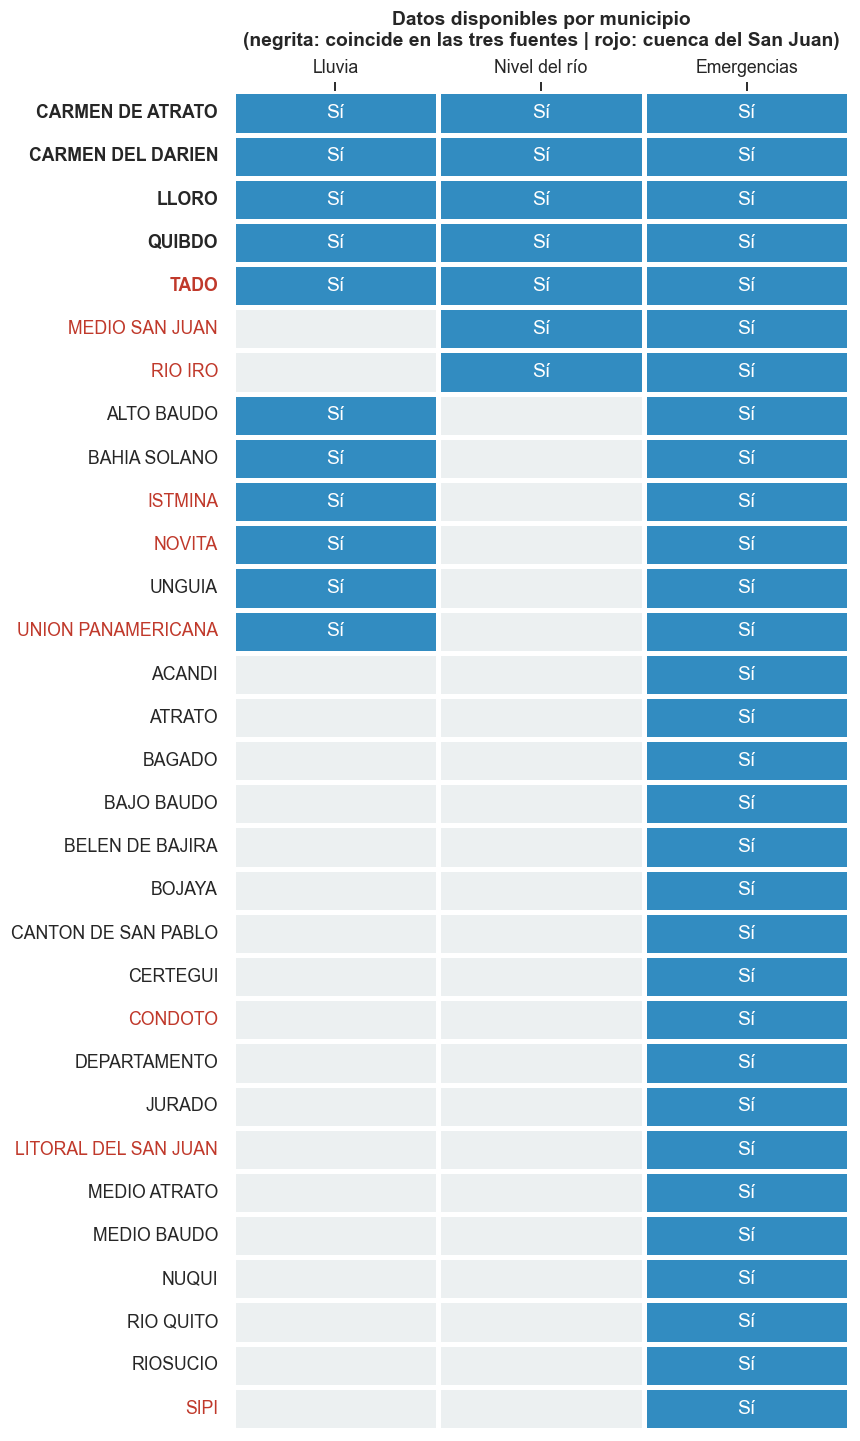

In [46]:
todos = sorted(mun_lluvia | mun_nivel | mun_emergencias)
coincidencias = pd.DataFrame({
    "Lluvia": [m in mun_lluvia for m in todos],
    "Nivel del río": [m in mun_nivel for m in todos],
    "Emergencias": [m in mun_emergencias for m in todos],
}, index=todos).astype(int)
coincidencias["total"] = coincidencias.sum(axis=1)
coincidencias = coincidencias.sort_values(["total", "Nivel del río"], ascending=False)

fig, ax = plt.subplots(figsize=(8, 0.38 * len(coincidencias) + 1.5))
sns.heatmap(coincidencias[["Lluvia", "Nivel del río", "Emergencias"]], cmap=["#ECF0F1", AZUL_RIO],
            cbar=False, linewidths=2, linecolor="white", ax=ax,
            annot=coincidencias[["Lluvia", "Nivel del río", "Emergencias"]].replace({1: "Sí", 0: ""}).values, fmt="")
ax.xaxis.tick_top()
ax.set_ylabel("")

for etiqueta in ax.get_yticklabels():
    if etiqueta.get_text() in MUNICIPIOS_COMUNES:
        etiqueta.set_fontweight("bold")
    if es_san_juan(etiqueta.get_text()):
        etiqueta.set_color(ROJO)

ax.set_title("Datos disponibles por municipio\n(negrita: coincide en las tres fuentes | rojo: cuenca del San Juan)", pad=30)
plt.tight_layout()
plt.show()

### 6.2 Inventario y mapa de estaciones

Azul: estaciones de lluvia. Naranja: estaciones de nivel del río. Gris: estaciones en municipios que no coinciden en las tres fuentes.
El tamaño del círculo indica qué tan completos están sus datos.

,CodigoEstacion,NombreEstacion,municipio,primer_dato,ultimo_dato,dias_con_datos,Latitud,Longitud,completitud_%,tipo,municipio_comun
0,0011025501,CARMEN DE ATRATO - AUT,CARMEN DE ATRATO,2023-01-01,2023-03-30,89,5.888719,-76.145167,8.1,Lluvia,True
1,0011027030,EL SIETE,CARMEN DE ATRATO,2024-09-04,2025-12-12,374,5.862000,-76.152056,34.1,Lluvia,True
2,0011027030,EL SIETE - AUT,CARMEN DE ATRATO,2023-01-02,2023-01-12,8,5.862000,-76.152056,0.7,Lluvia,True
21,0011027030,EL SIETE,CARMEN DE ATRATO,2024-09-04,2025-03-07,113,5.862000,-76.152056,10.3,Nivel,True
22,0011027030,EL SIETE - AUT,CARMEN DE ATRATO,2023-01-02,2023-03-17,75,5.862000,-76.152056,6.8,Nivel,True
19,1111700230,CURVARADO,CARMEN DEL DARIEN,2025-05-16,2025-12-12,201,7.159725,-76.964783,18.3,Lluvia,True
31,1111700230,CURVARADO,CARMEN DEL DARIEN,2025-05-16,2025-12-31,219,7.159725,-76.964783,20.0,Nivel,True
3,0011035010,LLORO,LLORO,2025-04-22,2025-12-12,146,5.510000,-76.580000,13.3,Lluvia,True
20,1117500060,LLORO,LLORO,2024-09-04,2025-04-22,91,5.510000,-76.580000,8.3,Lluvia,True
23,0011027070,BORAUDO,LLORO,2023-07-13,2025-12-30,154,5.515000,-76.576000,14.1,Nivel,True


Mapa interactivo guardado como mapa_estaciones.html (ábranlo con doble clic en el navegador)


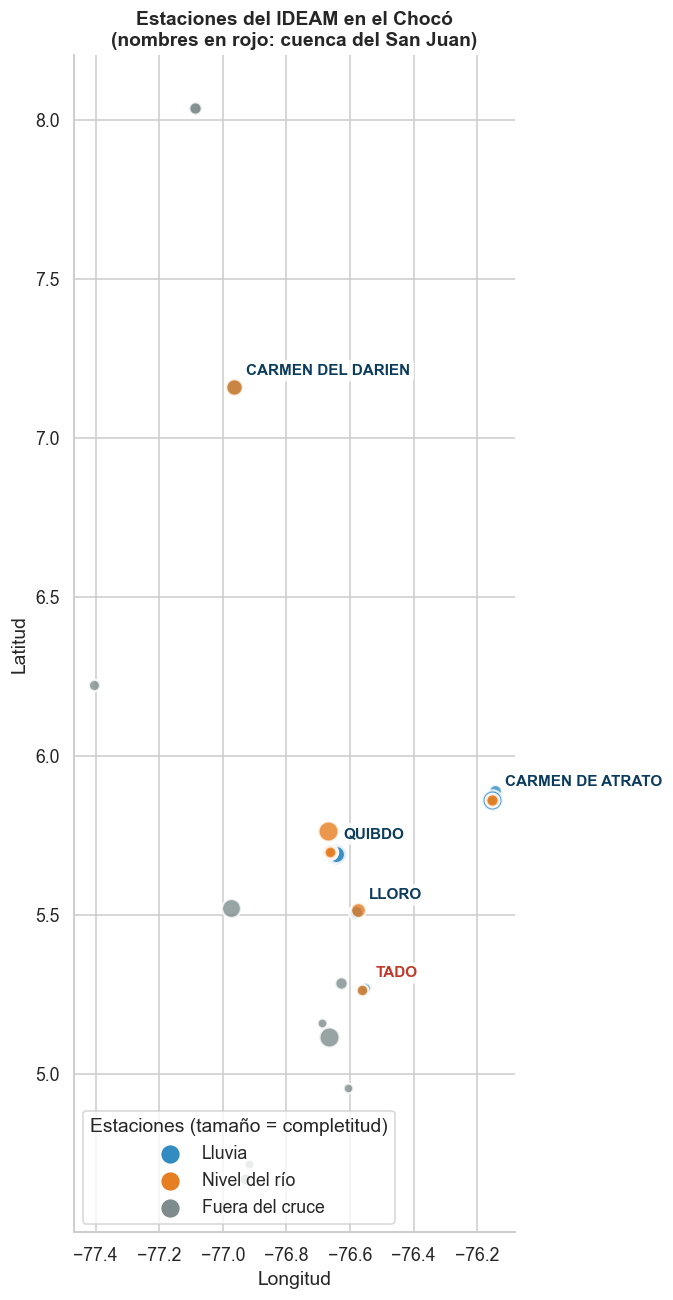

In [47]:
DIAS_PERIODO = (pd.Timestamp(FECHA_FIN) - pd.Timestamp(FECHA_INICIO)).days + 1


def inventario(df_original, df_diario, tipo):
    inv = df_diario.groupby(["CodigoEstacion", "NombreEstacion", "municipio"]).agg(
        primer_dato=("fecha", "min"),
        ultimo_dato=("fecha", "max"),
        dias_con_datos=("fecha", "nunique"),
    ).reset_index()
    coords = df_original.groupby("CodigoEstacion")[["Latitud", "Longitud"]].first().reset_index()
    inv = inv.merge(coords, on="CodigoEstacion", how="left")
    inv["completitud_%"] = (inv["dias_con_datos"] / DIAS_PERIODO * 100).round(1)
    inv["tipo"] = tipo
    inv["municipio_comun"] = inv["municipio"].isin(MUNICIPIOS_COMUNES)
    return inv


estaciones = pd.concat([inventario(lluvia, lluvia_estacion, "Lluvia"),
                        inventario(nivel, nivel_estacion, "Nivel")], ignore_index=True)
display(estaciones[estaciones["municipio_comun"]].sort_values(["municipio", "tipo"]))

con_coords = estaciones.dropna(subset=["Latitud", "Longitud"])


def color_estacion(est):
    if not est["municipio_comun"]:
        return GRIS
    return AZUL_RIO if est["tipo"] == "Lluvia" else NARANJA


# ---------- 1. Mapa interactivo (OpenStreetMap y Esri, gratuitos y sin registro) ----------
mapa = folium.Map(location=[5.5, -76.8], zoom_start=8, tiles=None)
folium.TileLayer("OpenStreetMap", name="Calles (OpenStreetMap)").add_to(mapa)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satélite (Esri)").add_to(mapa)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri", name="Relieve (Esri)").add_to(mapa)

for _, est in con_coords.iterrows():
    color = color_estacion(est)
    folium.CircleMarker(
        location=[est["Latitud"], est["Longitud"]],
        radius=4 + est["completitud_%"] / 12,
        color=color, fill=True, fill_color=color, fill_opacity=0.8,
        popup=folium.Popup(f"<b>{est['NombreEstacion']}</b><br>{est['tipo']} - {est['municipio']}<br>"
                           f"Completitud: {est['completitud_%']}%", max_width=250),
    ).add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa.save("mapa_estaciones.html")
print("Mapa interactivo guardado como mapa_estaciones.html (ábranlo con doble clic en el navegador)")
display(mapa)


# ---------- 2. Mapa estático (siempre se ve y sirve para el informe) ----------
fig, ax = plt.subplots(figsize=(10, 12))

for _, est in con_coords.iterrows():
    ax.scatter(est["Longitud"], est["Latitud"], s=40 + est["completitud_%"] * 4,
               color=color_estacion(est), alpha=0.8, edgecolor="white", linewidth=1.5, zorder=3)

# Nombre de cada municipio común, en la posición promedio de sus estaciones
etiquetas = con_coords[con_coords["municipio_comun"]].groupby("municipio")[["Longitud", "Latitud"]].mean()
for mun, fila in etiquetas.iterrows():
    ax.annotate(mun, (fila["Longitud"], fila["Latitud"]), xytext=(8, 8), textcoords="offset points",
                fontsize=10, fontweight="bold", color=ROJO if es_san_juan(mun) else AZUL_PROFUNDO,
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", alpha=0.8, edgecolor="none"))

for etiqueta, color in [("Lluvia", AZUL_RIO), ("Nivel del río", NARANJA), ("Fuera del cruce", GRIS)]:
    ax.scatter([], [], s=120, color=color, label=etiqueta)
ax.legend(title="Estaciones (tamaño = completitud)", loc="lower left", frameon=True)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_aspect("equal")
ax.set_title("Estaciones del IDEAM en el Chocó\n(nombres en rojo: cuenca del San Juan)")
plt.tight_layout()
plt.show()

### 6.3 ¿Qué tan completos están los datos?

Porcentaje de días de cada mes con datos, para las estaciones de los municipios comunes.

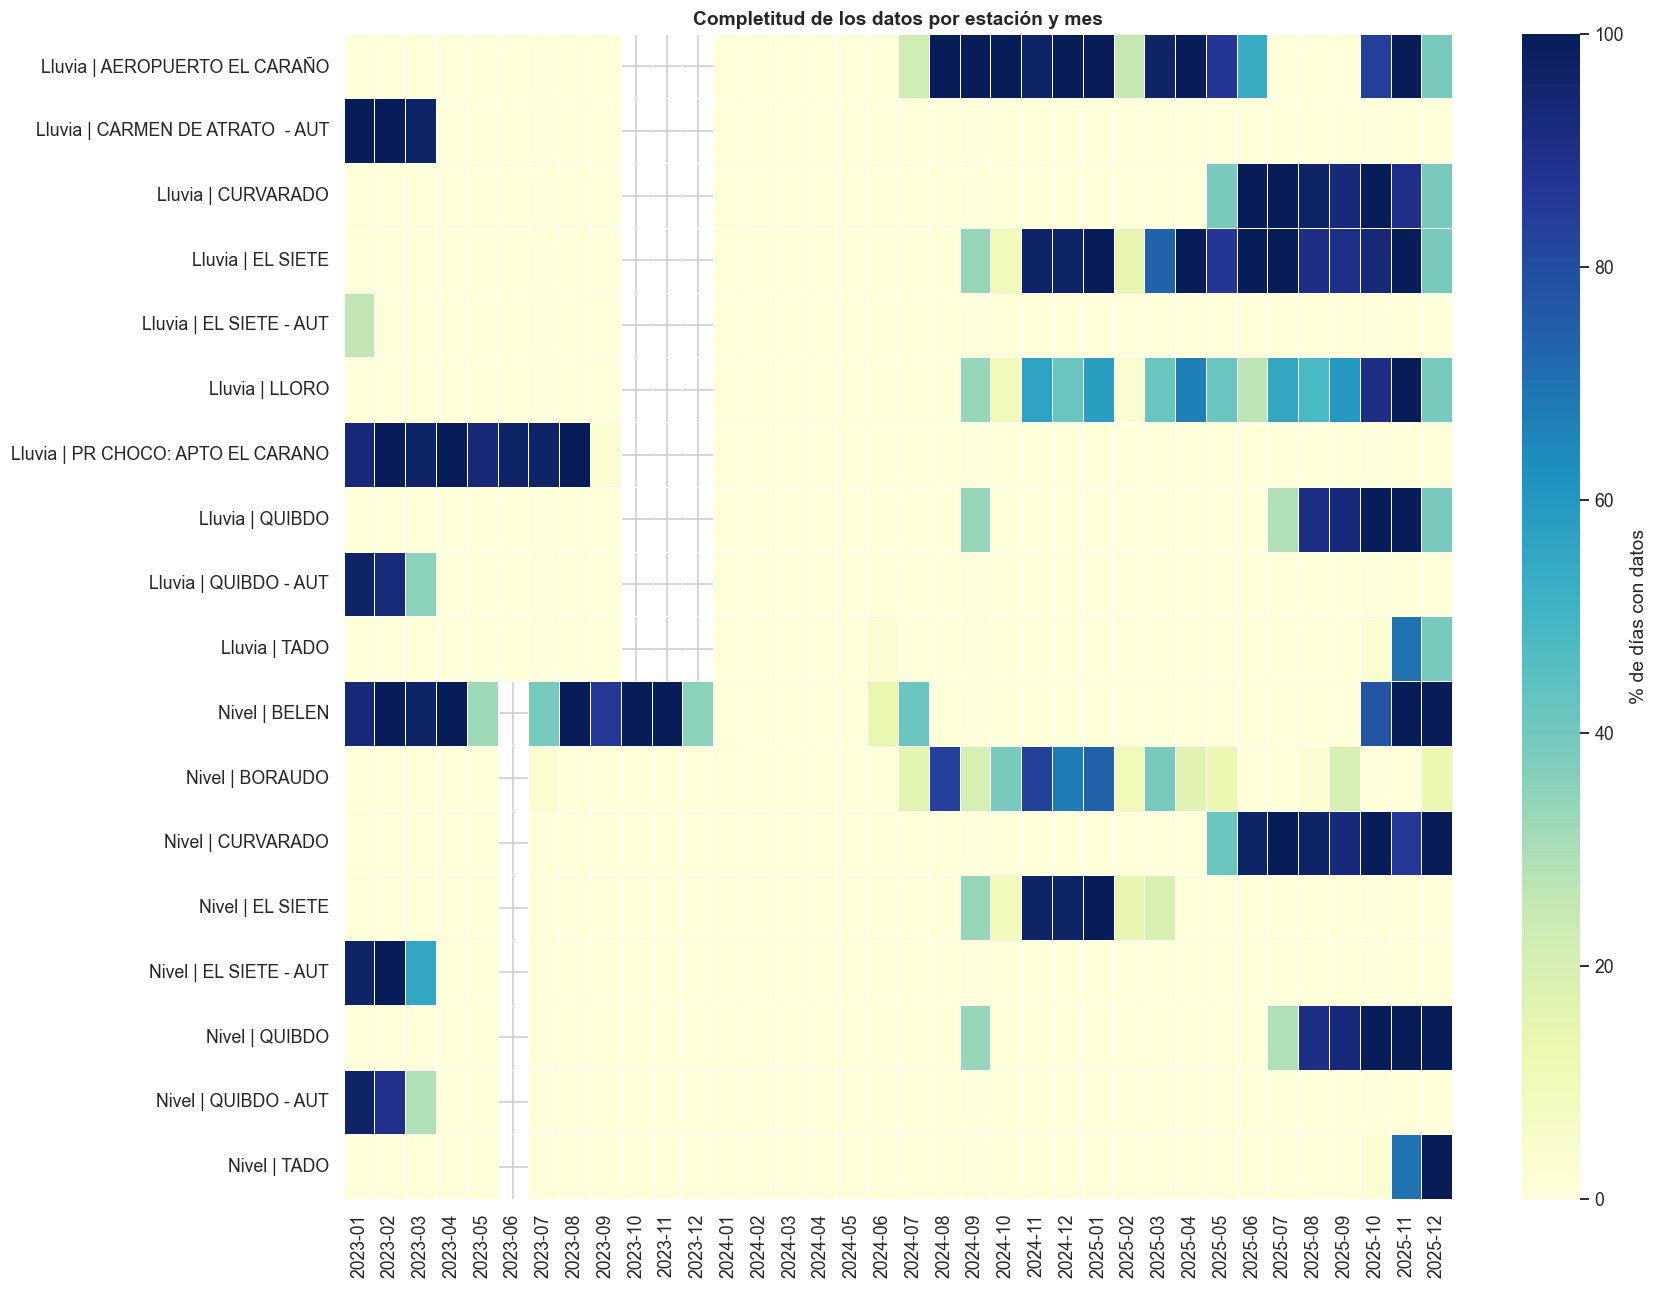

In [48]:
def completitud_mensual(df_diario, tipo):
    df_diario = df_diario[df_diario["municipio"].isin(MUNICIPIOS_COMUNES)]
    tabla = df_diario.groupby(["NombreEstacion", df_diario["fecha"].dt.to_period("M")])["fecha"].nunique().unstack(fill_value=0)
    tabla = tabla.div(tabla.columns.days_in_month, axis=1) * 100
    tabla.index = [f"{tipo} | {nombre}" for nombre in tabla.index]
    return tabla


completitud = pd.concat([completitud_mensual(lluvia_estacion, "Lluvia"),
                         completitud_mensual(nivel_estacion, "Nivel")])
completitud = completitud.reindex(columns=pd.period_range(FECHA_INICIO, FECHA_FIN, freq="M"), fill_value=0)

fig, ax = plt.subplots(figsize=(16, 0.55 * len(completitud) + 2))
sns.heatmap(completitud, cmap="YlGnBu", vmin=0, vmax=100, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "% de días con datos"}, ax=ax)
ax.set_xticklabels([str(p) for p in completitud.columns], rotation=90)
ax.set_title("Completitud de los datos por estación y mes")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 7. Dataframe combinado: una fila por municipio y por día

Para cada municipio común se combinan las tres fuentes:

- **Lluvia:** promedio de las estaciones del municipio (y el máximo entre ellas).
- **Nivel:** si un municipio tiene varias estaciones de nivel, se usa la que tenga más días de datos, porque cada estación mide un punto distinto del río y no se pueden promediar.
- **Emergencias:** número de emergencias hidrológicas y familias afectadas ese día.

Como cada río tiene una escala distinta, se calcula también el **percentil del nivel** dentro de su propio municipio (0 = el nivel más bajo registrado, 100 = el más alto). Así los municipios se pueden comparar entre sí.

Al final se marcan como **aptos para el modelo** los municipios con al menos 60 días en que haya lluvia y nivel al mismo tiempo. Los demás se usan solo en la parte descriptiva.

In [49]:
# Lluvia por municipio y día
lluvia_mun = lluvia_estacion[lluvia_estacion["municipio"].isin(MUNICIPIOS_COMUNES)].groupby(["municipio", "fecha"]).agg(
    lluvia_mm=("lluvia_mm", "mean"),
    lluvia_max_mm=("lluvia_mm", "max"),
    estaciones_lluvia=("CodigoEstacion", "nunique"),
).reset_index()

# Estación principal de nivel en cada municipio
nivel_comun = nivel_estacion[nivel_estacion["municipio"].isin(MUNICIPIOS_COMUNES)]
dias_por_estacion = nivel_comun.groupby(["municipio", "CodigoEstacion", "NombreEstacion"])["fecha"].nunique().reset_index()
estacion_principal = dias_por_estacion.sort_values("fecha", ascending=False).drop_duplicates("municipio")
print("Estación de nivel usada en cada municipio:")
display(estacion_principal.rename(columns={"fecha": "dias_con_datos"}))

nivel_mun = nivel_comun[nivel_comun["CodigoEstacion"].isin(estacion_principal["CodigoEstacion"])]
nivel_mun = nivel_mun[["municipio", "fecha", "nivel_max", "nivel_medio", "nivel_min"]]

# Emergencias hidrológicas por municipio y día
eventos_mun = hidrologicas[hidrologicas["municipio"].isin(MUNICIPIOS_COMUNES)].groupby(["municipio", "fecha"]).agg(
    eventos=("evento", "size"),
    familias_afectadas=("familias", "sum"),
).reset_index()

# Tabla base: todos los días para todos los municipios comunes
base = pd.MultiIndex.from_product([MUNICIPIOS_COMUNES, pd.date_range(FECHA_INICIO, FECHA_FIN)],
                                  names=["municipio", "fecha"]).to_frame(index=False)

df = (base.merge(lluvia_mun, on=["municipio", "fecha"], how="left")
          .merge(nivel_mun, on=["municipio", "fecha"], how="left")
          .merge(eventos_mun, on=["municipio", "fecha"], how="left"))

df["eventos"] = df["eventos"].fillna(0).astype(int)
df["familias_afectadas"] = df["familias_afectadas"].fillna(0)
df["hubo_evento"] = (df["eventos"] > 0).astype(int)
df["cuenca_san_juan"] = df["municipio"].apply(es_san_juan).astype(int)
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month

# Variables derivadas (calculadas dentro de cada municipio)
df = df.sort_values(["municipio", "fecha"])
por_mun = df.groupby("municipio")
df["lluvia_acum_3d"] = por_mun["lluvia_mm"].transform(lambda x: x.rolling(3, min_periods=2).sum())
df["lluvia_acum_7d"] = por_mun["lluvia_mm"].transform(lambda x: x.rolling(7, min_periods=5).sum())
df["nivel_dia_anterior"] = por_mun["nivel_max"].shift(1)
df["cambio_nivel"] = por_mun["nivel_max"].diff()
df["nivel_percentil"] = por_mun["nivel_max"].rank(pct=True) * 100

# Umbral de nivel alto: percentil 95 de cada municipio
df["umbral_nivel"] = por_mun["nivel_max"].transform(lambda x: x.quantile(0.95))
df["nivel_alto"] = np.where(df["nivel_max"].isna(), np.nan, (df["nivel_max"] >= df["umbral_nivel"]).astype(int))

# Municipios con suficientes días de lluvia y nivel al mismo tiempo
MIN_DIAS_COMUNES = 60
dias_comunes = df.assign(ambos=df["lluvia_mm"].notna() & df["nivel_max"].notna()).groupby("municipio")["ambos"].sum()
MUNICIPIOS_MODELO = sorted(dias_comunes[dias_comunes >= MIN_DIAS_COMUNES].index)
df["apto_modelo"] = df["municipio"].isin(MUNICIPIOS_MODELO).astype(int)

print("Forma del dataframe:", df.shape)
print(f"\nMunicipios con al menos {MIN_DIAS_COMUNES} días con lluvia y nivel a la vez (aptos para el modelo):")
for m in MUNICIPIOS_MODELO:
    print(f"  - {m}: {dias_comunes[m]} días")
print("Municipios solo para análisis descriptivo:", sorted(set(MUNICIPIOS_COMUNES) - set(MUNICIPIOS_MODELO)))
df.head()

Estación de nivel usada en cada municipio:


,municipio,CodigoEstacion,NombreEstacion,dias_con_datos
4,QUIBDO,0011047010,BELEN,370
2,CARMEN DEL DARIEN,1111700230,CURVARADO,219
3,LLORO,0011027070,BORAUDO,154
0,CARMEN DE ATRATO,0011027030,EL SIETE,113
8,TADO,0054017040,TADO,53


Forma del dataframe: (5480, 22)

Municipios con al menos 60 días con lluvia y nivel a la vez (aptos para el modelo):
  - CARMEN DE ATRATO: 188 días
  - CARMEN DEL DARIEN: 199 días
  - LLORO: 61 días
  - QUIBDO: 239 días
Municipios solo para análisis descriptivo: ['TADO']


,municipio,fecha,lluvia_mm,lluvia_max_mm,estaciones_lluvia,nivel_max,nivel_medio,nivel_min,eventos,familias_afectadas,...,anio,mes,lluvia_acum_3d,lluvia_acum_7d,nivel_dia_anterior,cambio_nivel,nivel_percentil,umbral_nivel,nivel_alto,apto_modelo
0,CARMEN DE ATRATO,2023-01-01,0.10,0.1,1.0,NaN,NaN,NaN,0,0.0,...,2023,1,NaN,NaN,NaN,NaN,NaN,1.833,NaN,1
1,CARMEN DE ATRATO,2023-01-02,3.70,7.4,2.0,1.62,1.523636,1.45,0,0.0,...,2023,1,3.80,NaN,NaN,NaN,65.957447,1.833,0.0,1
2,CARMEN DE ATRATO,2023-01-03,14.35,28.6,2.0,2.18,1.756250,1.52,0,0.0,...,2023,1,18.15,NaN,1.62,0.56,100.000000,1.833,1.0,1
3,CARMEN DE ATRATO,2023-01-04,0.05,0.1,2.0,1.72,1.623913,1.57,0,0.0,...,2023,1,18.10,NaN,2.18,-0.46,86.436170,1.833,0.0,1
4,CARMEN DE ATRATO,2023-01-05,0.00,0.0,1.0,1.63,1.573750,1.51,0,0.0,...,2023,1,14.40,18.2,1.72,-0.09,69.414894,1.833,0.0,1


In [50]:
# Resumen por municipio
resumen = df.groupby("municipio").agg(
    dias_con_lluvia=("lluvia_mm", "count"),
    dias_con_nivel=("nivel_max", "count"),
    dias_lluvia_y_nivel=("apto_modelo", lambda x: (df.loc[x.index, "lluvia_mm"].notna() & df.loc[x.index, "nivel_max"].notna()).sum()),
    lluvia_media_mm=("lluvia_mm", "mean"),
    lluvia_total_mm=("lluvia_mm", "sum"),
    umbral_nivel=("umbral_nivel", "first"),
    emergencias=("eventos", "sum"),
    familias_afectadas=("familias_afectadas", "sum"),
).round(1)
resumen

,dias_con_lluvia,dias_con_nivel,dias_lluvia_y_nivel,lluvia_media_mm,lluvia_total_mm,umbral_nivel,emergencias,familias_afectadas
municipio,,,,,,,,
CARMEN DE ATRATO,463,188,188,1.3,589.7,1.8,2,100.0
CARMEN DEL DARIEN,201,219,199,7.7,1546.9,5.8,9,2540.0
LLORO,236,154,61,24.1,5678.8,7.4,7,4074.0
QUIBDO,676,370,239,22.0,14898.4,9.9,14,1433.0
TADO,35,53,34,21.7,758.8,4.2,2,467.0


In [51]:
# Datos faltantes por variable
faltantes = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
faltantes[faltantes > 0].to_frame("% faltante")

,% faltante
cambio_nivel,83.4
nivel_dia_anterior,82.1
nivel_max,82.0
nivel_medio,82.0
nivel_min,82.0
nivel_alto,82.0
nivel_percentil,82.0
lluvia_acum_7d,71.7
lluvia_mm,70.6
lluvia_max_mm,70.6


## 8. Análisis exploratorio

### 8.1 ¿Qué desastres golpean al Chocó?

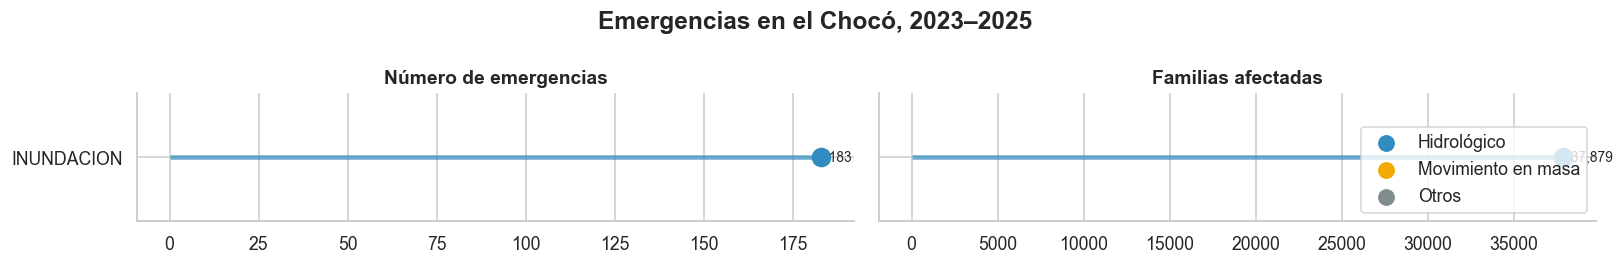

In [52]:
conteo = emergencias.groupby(["evento", "grupo"]).agg(
    casos=("evento", "size"), familias=("familias", "sum")).reset_index().sort_values("casos")
colores_grupo = {"Hidrológico": AZUL_RIO, "Movimiento en masa": AMARILLO, "Otros": GRIS}

fig, axes = plt.subplots(1, 2, figsize=(15, 0.45 * len(conteo) + 2), sharey=True)
for ax, columna, titulo in [(axes[0], "casos", "Número de emergencias"),
                            (axes[1], "familias", "Familias afectadas")]:
    colores = conteo["grupo"].map(colores_grupo)
    ax.hlines(conteo["evento"], 0, conteo[columna], color=colores, linewidth=3, alpha=0.7)
    ax.scatter(conteo[columna], conteo["evento"], color=colores, s=140, zorder=3)
    for y, x in zip(conteo["evento"], conteo[columna]):
        ax.text(x, y, f"  {x:,.0f}", va="center", fontsize=9)
    ax.set_title(titulo)

for grupo, color in colores_grupo.items():
    axes[1].scatter([], [], color=color, s=100, label=grupo)
axes[1].legend(loc="lower right", frameon=True)
fig.suptitle("Emergencias en el Chocó, 2023–2025", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### 8.2 ¿Dónde y cuándo ocurren las emergencias hidrológicas?

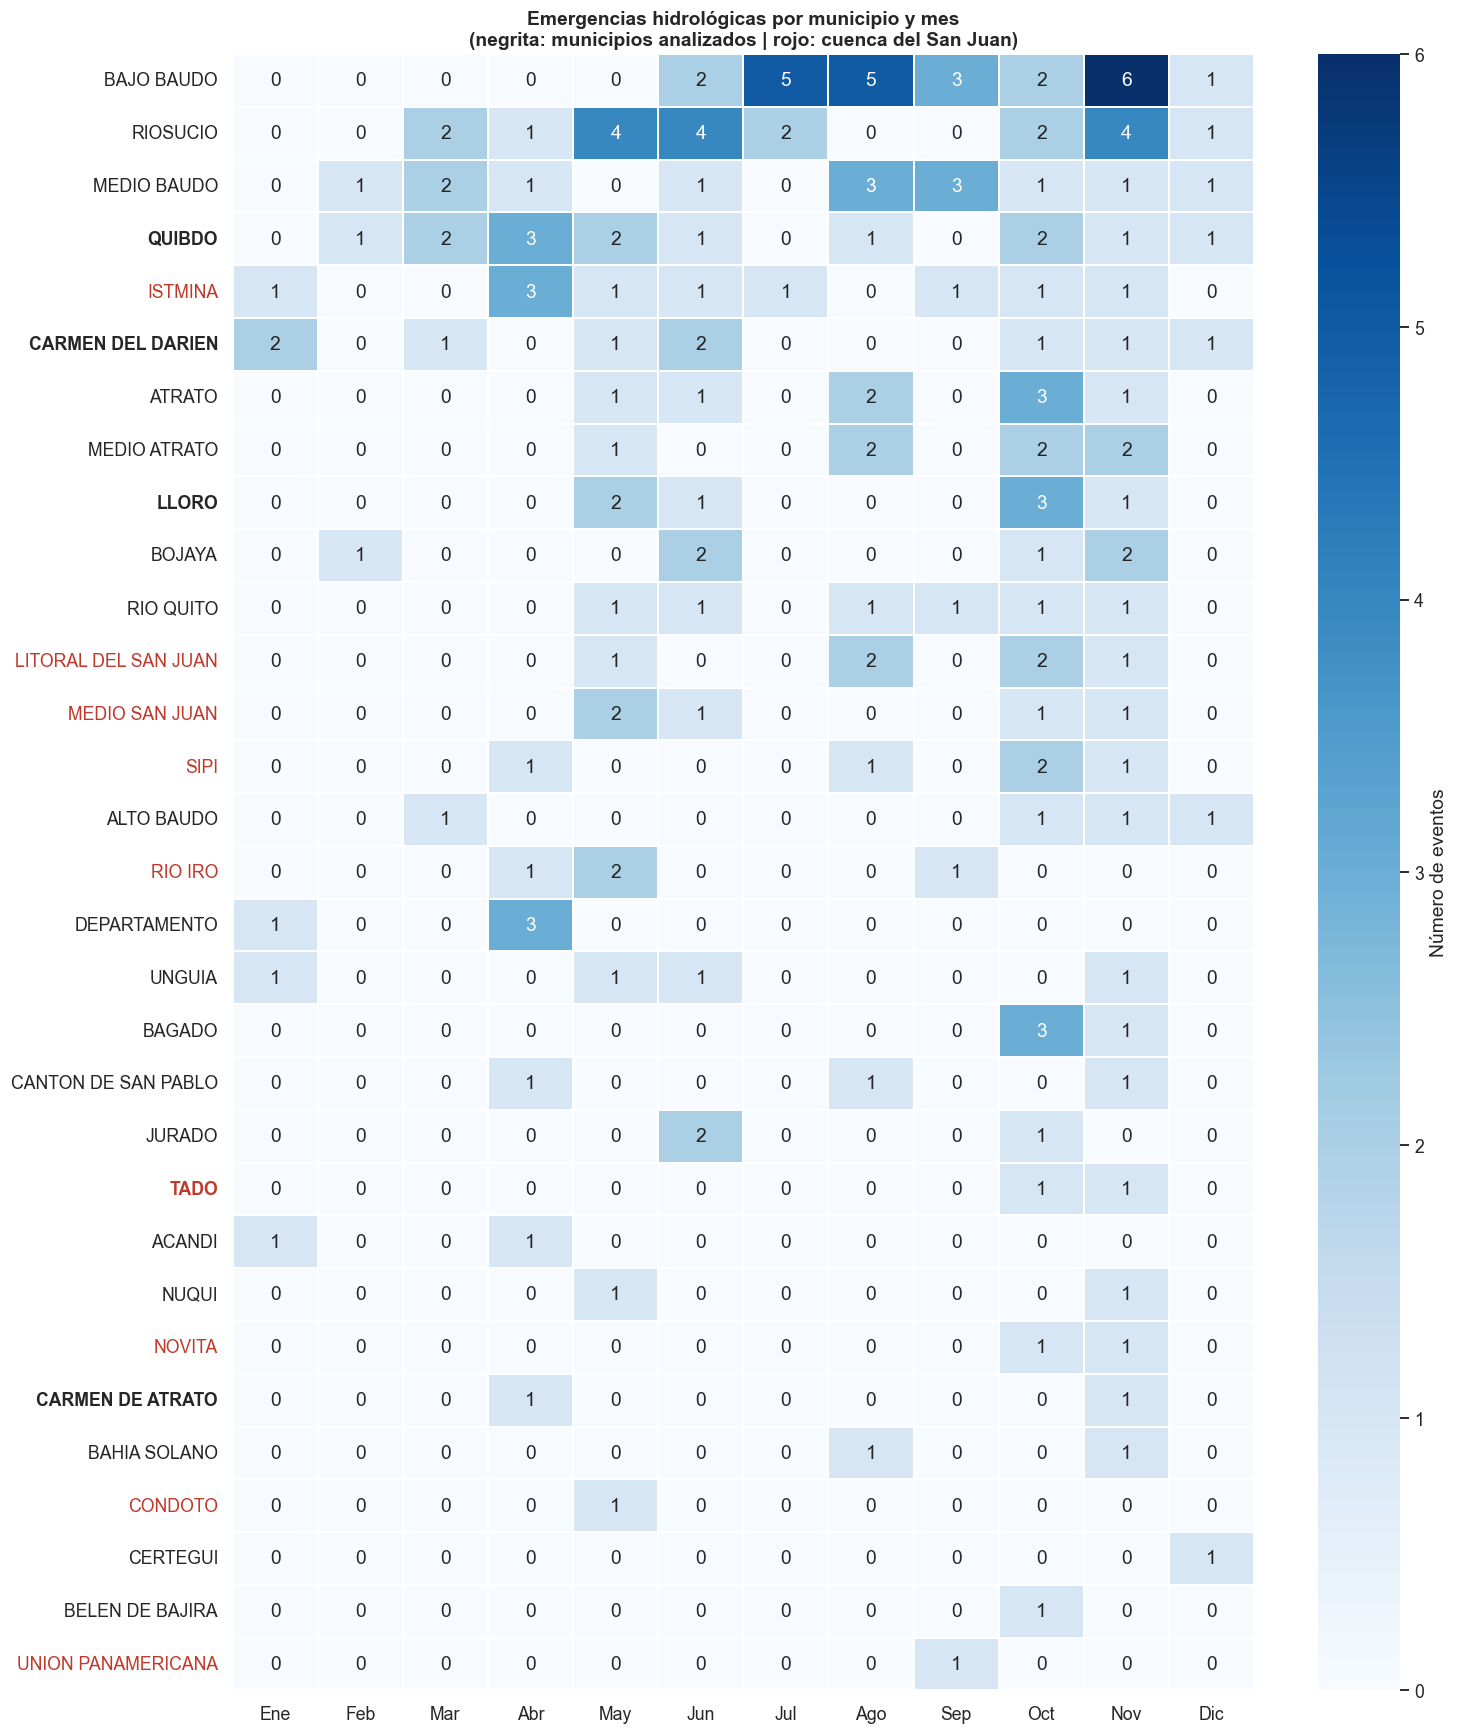

In [53]:
tabla = hidrologicas.pivot_table(index="municipio", columns=hidrologicas["fecha"].dt.month,
                                 values="evento", aggfunc="size", fill_value=0)
tabla = tabla.reindex(columns=range(1, 13), fill_value=0)
tabla = tabla.loc[tabla.sum(axis=1).sort_values(ascending=False).index]
tabla.columns = MESES

fig, ax = plt.subplots(figsize=(14, 0.45 * len(tabla) + 2))
sns.heatmap(tabla, cmap="Blues", annot=True, fmt="d", linewidths=1, linecolor="white",
            cbar_kws={"label": "Número de eventos"}, ax=ax)
for etiqueta in ax.get_yticklabels():
    if etiqueta.get_text() in MUNICIPIOS_COMUNES:
        etiqueta.set_fontweight("bold")
    if es_san_juan(etiqueta.get_text()):
        etiqueta.set_color(ROJO)
ax.set_title("Emergencias hidrológicas por municipio y mes\n(negrita: municipios analizados | rojo: cuenca del San Juan)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 8.3 El pulso de cada río

Una gráfica por municipio. Arriba, la lluvia **cuelga como si cayera del cielo** (barras invertidas); abajo, el nivel del río.
Los triángulos rojos marcan las emergencias reportadas y la línea punteada, el umbral de nivel alto de ese municipio.

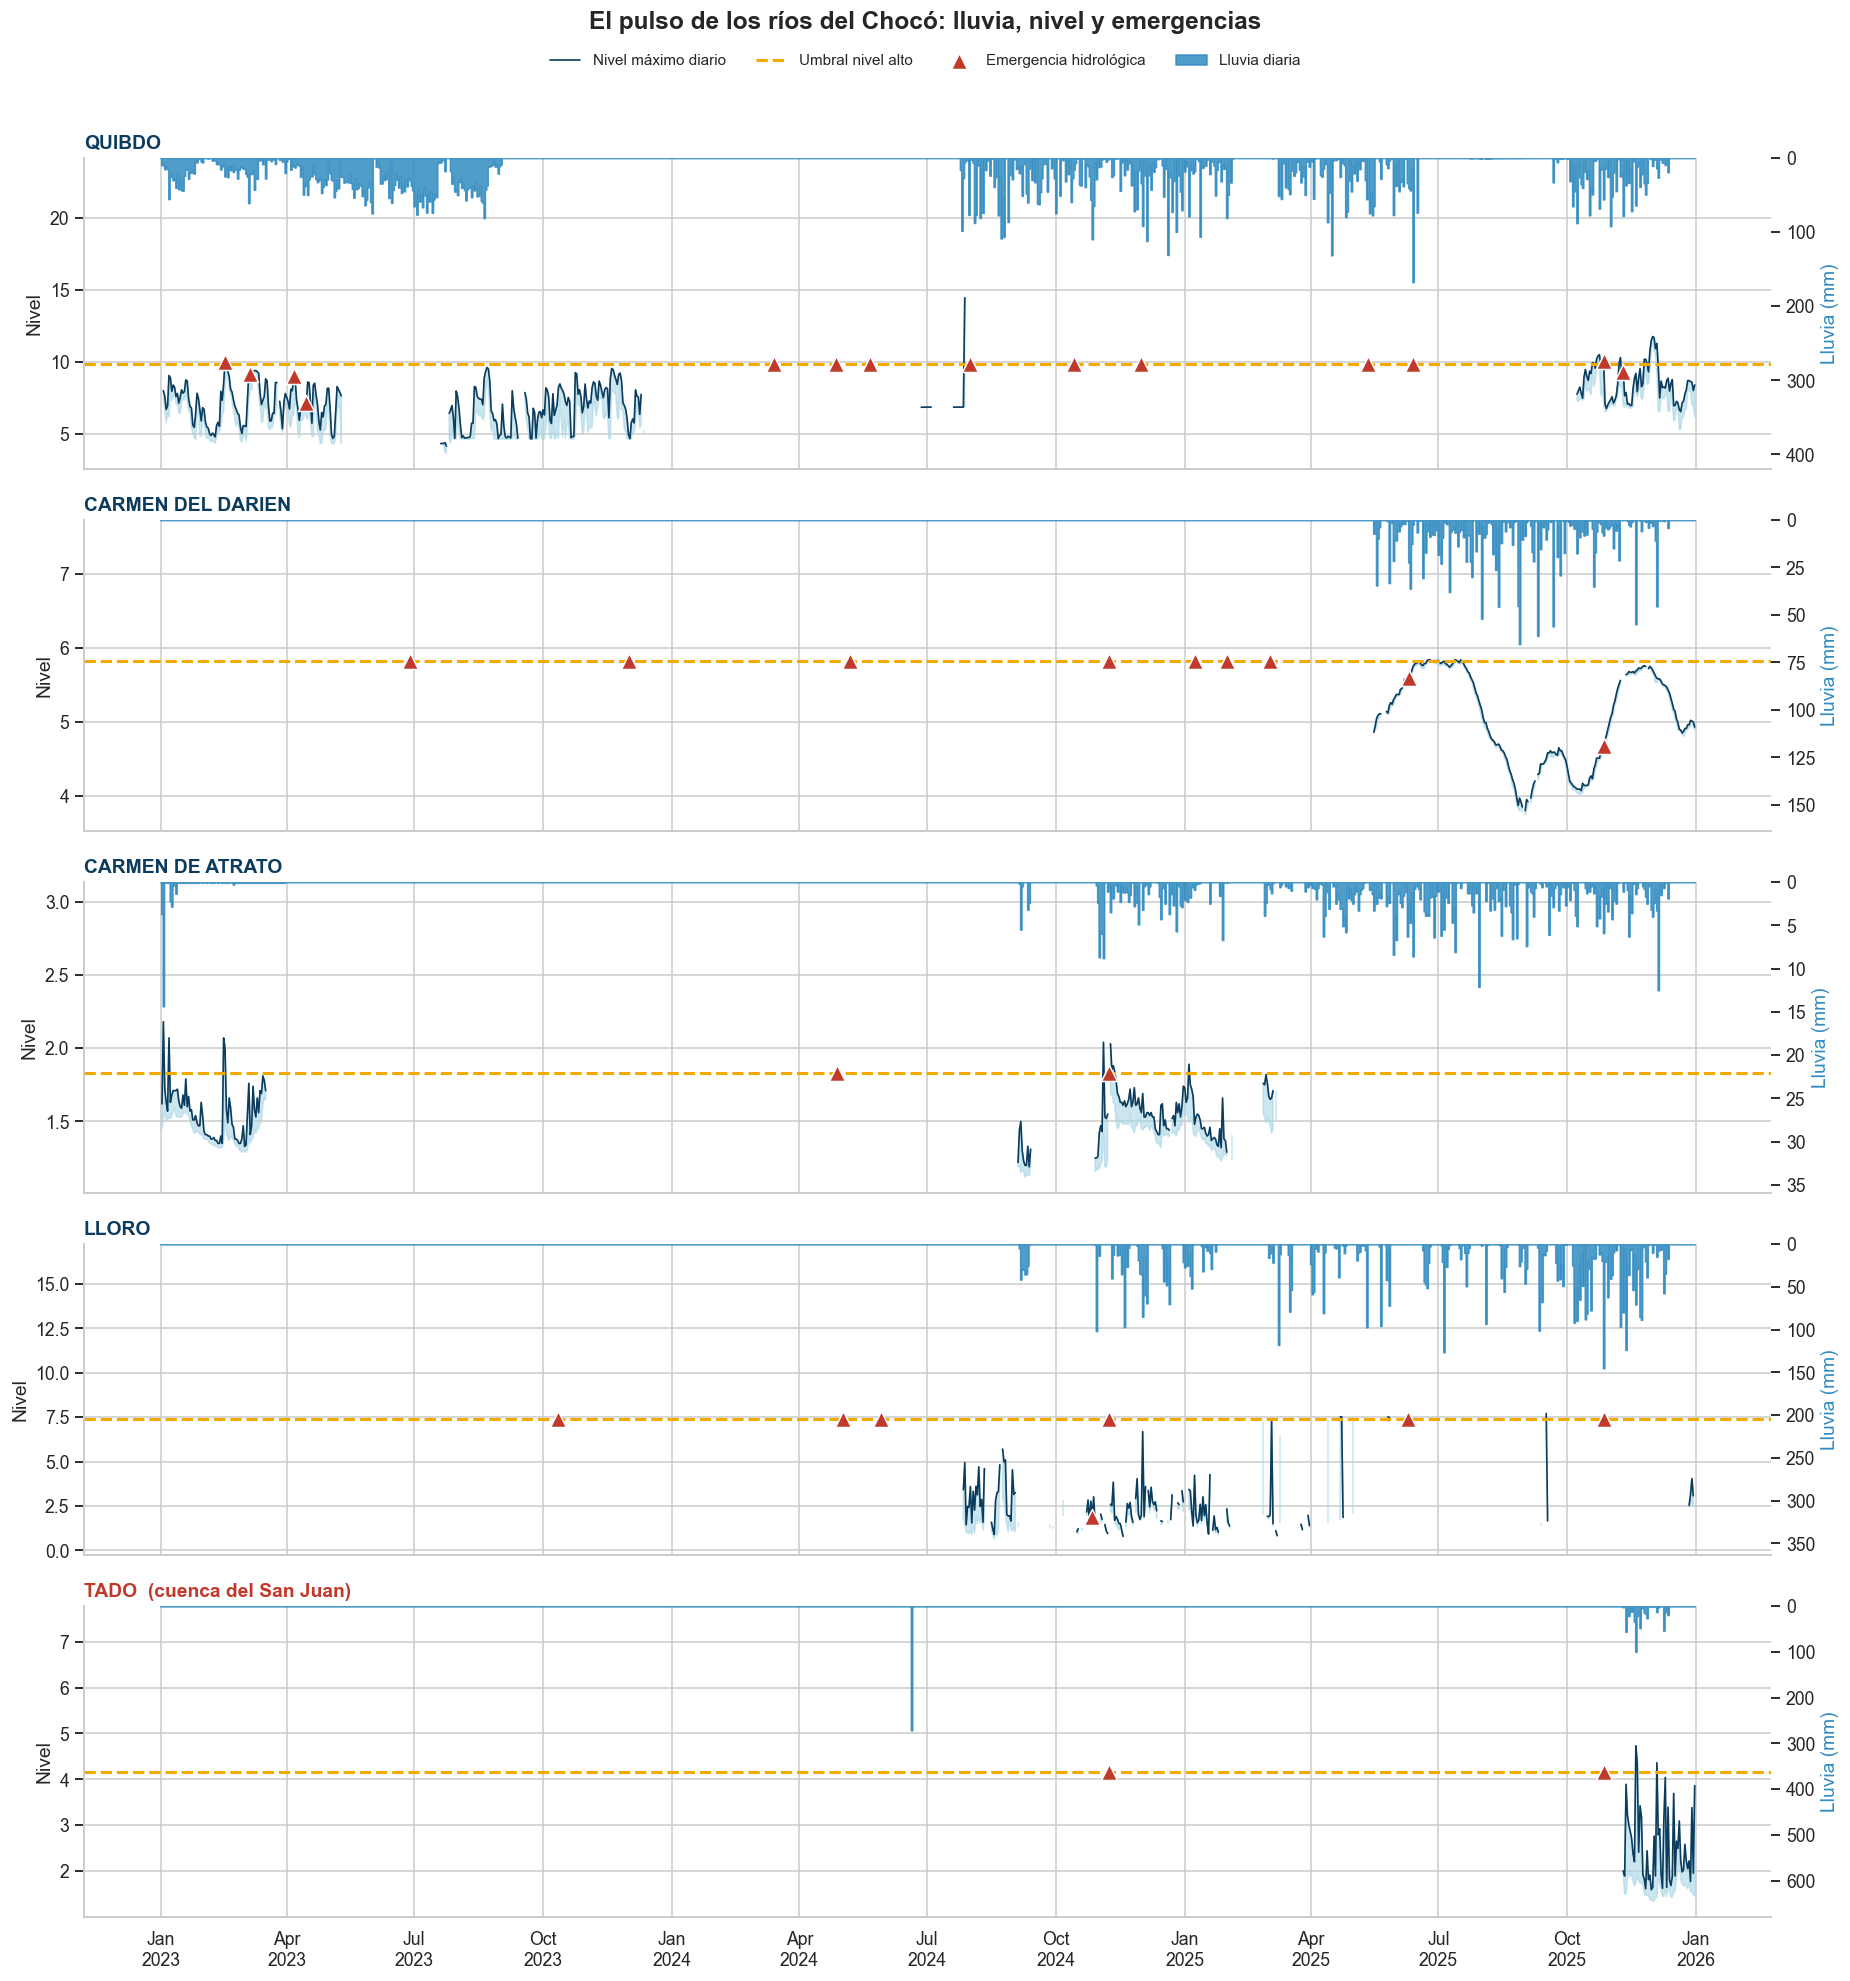

In [54]:
municipios_graf = df.groupby("municipio")["nivel_max"].count().sort_values(ascending=False).index[:8]
fig, axes = plt.subplots(len(municipios_graf), 1, figsize=(17, 3.6 * len(municipios_graf)), sharex=True)

for ax, mun in zip(np.atleast_1d(axes), municipios_graf):
    d = df[df["municipio"] == mun]
    umbral = d["umbral_nivel"].iloc[0]

    ax.fill_between(d["fecha"], d["nivel_min"], d["nivel_max"], color=AZUL_CLARO, alpha=0.6)
    ax.plot(d["fecha"], d["nivel_max"], color=AZUL_PROFUNDO, linewidth=1.1, label="Nivel máximo diario")
    ax.axhline(umbral, color=AMARILLO, linestyle="--", linewidth=2, label="Umbral nivel alto")
    ev = d[d["hubo_evento"] == 1]
    ax.scatter(ev["fecha"], ev["nivel_max"].fillna(umbral), marker="^", s=110, color=ROJO,
               edgecolor="white", zorder=5, label="Emergencia hidrológica")

    bajo, alto = d["nivel_min"].min(), d["nivel_max"].max()
    if pd.notna(bajo) and pd.notna(alto):
        ax.set_ylim(bajo - 0.1 * (alto - bajo), alto + 0.9 * (alto - bajo))
    ax.set_ylabel("Nivel")

    ax2 = ax.twinx()
    ax2.fill_between(d["fecha"], 0, d["lluvia_mm"].fillna(0), step="mid", color=AZUL_RIO, alpha=0.85, label="Lluvia diaria")
    ax2.set_ylim(max(d["lluvia_mm"].max(), 1) * 2.5, 0)
    ax2.set_ylabel("Lluvia (mm)", color=AZUL_RIO)
    ax2.grid(False)

    color_titulo = ROJO if es_san_juan(mun) else AZUL_PROFUNDO
    ax.set_title(f"{mun}{'  (cuenca del San Juan)' if es_san_juan(mun) else ''}", loc="left", color=color_titulo)

lineas1, etiq1 = np.atleast_1d(axes)[0].get_legend_handles_labels()
lineas2, etiq2 = ax2.get_legend_handles_labels()
fig.legend(lineas1 + lineas2, etiq1 + etiq2, loc="upper center", ncol=4, fontsize=10, frameon=False,
           bbox_to_anchor=(0.5, 0.985))
np.atleast_1d(axes)[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
np.atleast_1d(axes)[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.suptitle("El pulso de los ríos del Chocó: lluvia, nivel y emergencias", fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 8.4 ¿Qué municipio es más lluvioso?

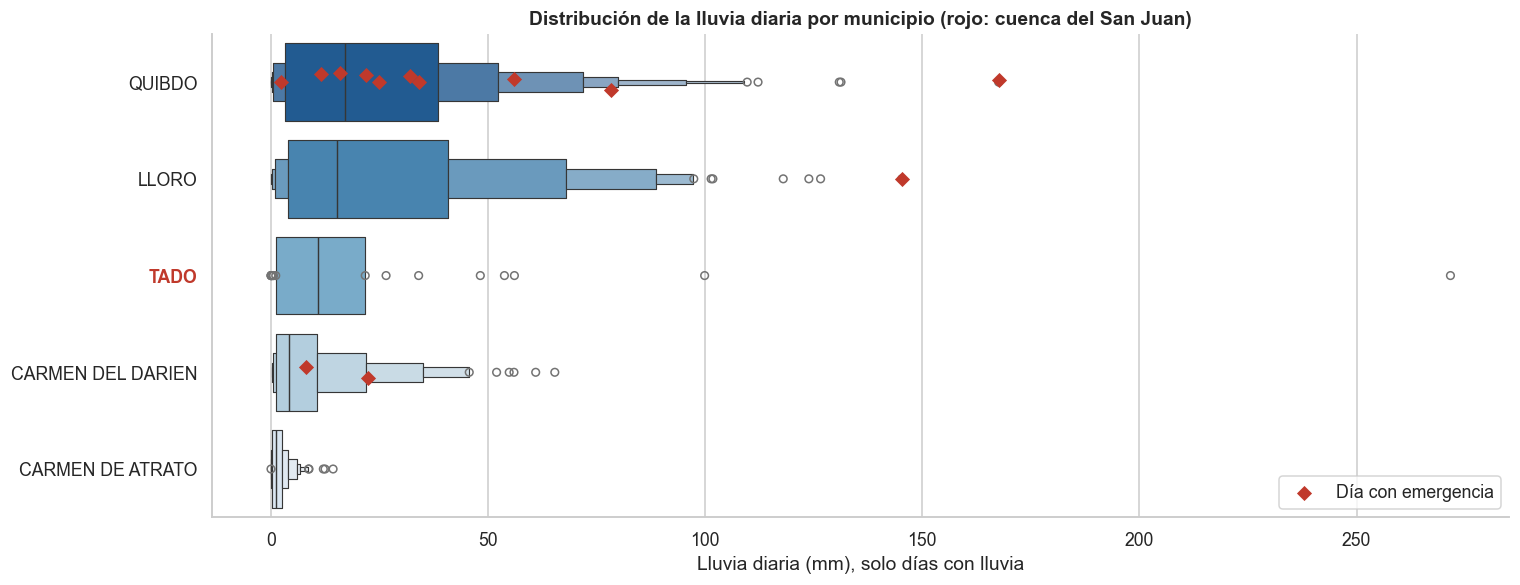

In [55]:
orden = df.groupby("municipio")["lluvia_mm"].median().sort_values(ascending=False).index
dias_lluvia = df[df["lluvia_mm"] > 0]

fig, ax = plt.subplots(figsize=(14, 0.7 * len(orden) + 2))
sns.boxenplot(data=dias_lluvia, y="municipio", x="lluvia_mm", order=orden, palette="Blues_r", ax=ax)
sns.stripplot(data=dias_lluvia[dias_lluvia["hubo_evento"] == 1], y="municipio", x="lluvia_mm", order=orden,
              color=ROJO, size=7, marker="D", ax=ax, label="Día con emergencia")

for etiqueta in ax.get_yticklabels():
    if es_san_juan(etiqueta.get_text()):
        etiqueta.set_color(ROJO)
        etiqueta.set_fontweight("bold")

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:1], labels[:1], loc="lower right")
ax.set_xlabel("Lluvia diaria (mm), solo días con lluvia")
ax.set_ylabel("")
ax.set_title("Distribución de la lluvia diaria por municipio (rojo: cuenca del San Juan)")
plt.tight_layout()
plt.show()

### 8.5 Calendario de lluvias

Cada cuadro es un día; mientras más oscuro, más llovió (promedio de los municipios analizados).
Los cuadros con borde rojo son días con al menos una emergencia hidrológica.

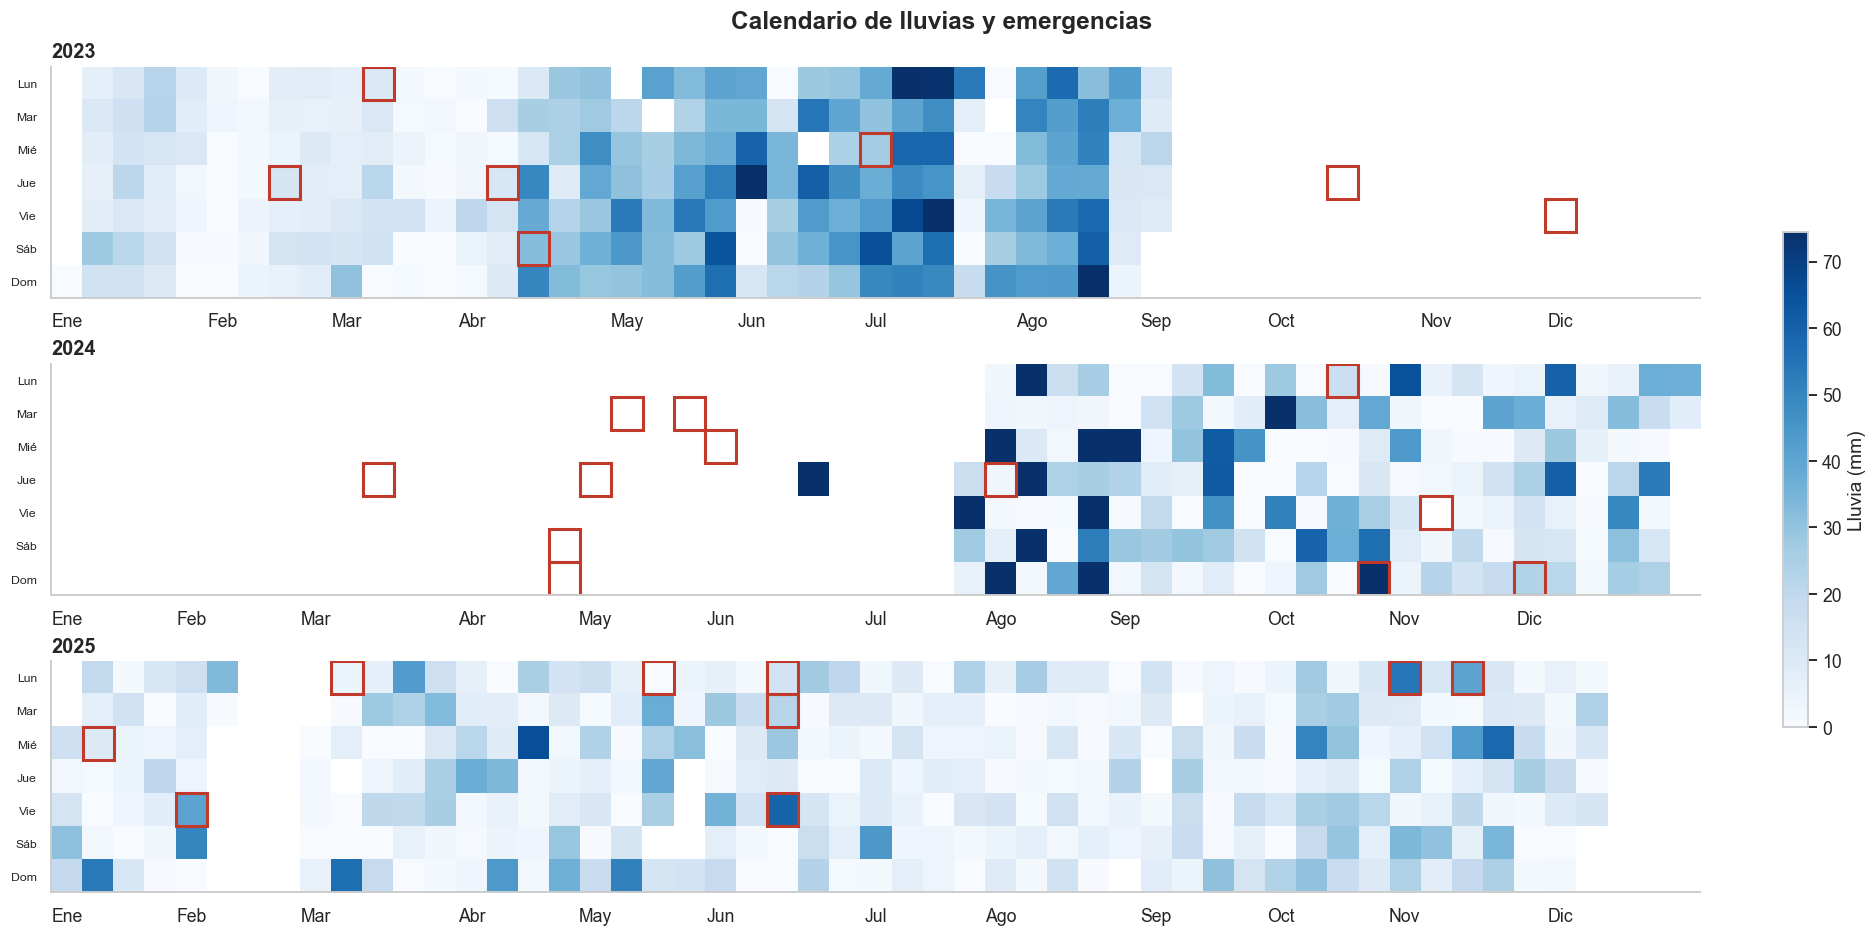

In [56]:
diario = df.groupby("fecha").agg(lluvia_mm=("lluvia_mm", "mean"), eventos=("eventos", "sum")).reset_index()
diario["anio"] = diario["fecha"].dt.year
anios = sorted(diario["anio"].unique())
vmax = diario["lluvia_mm"].quantile(0.98)

fig, axes = plt.subplots(len(anios), 1, figsize=(17, 2.8 * len(anios)), constrained_layout=True)
for ax, anio in zip(np.atleast_1d(axes), anios):
    d = diario[diario["anio"] == anio].copy()
    primer_dia = pd.Timestamp(anio, 1, 1).weekday()
    d["semana"] = (d["fecha"].dt.dayofyear - 1 + primer_dia) // 7
    d["dia_semana"] = d["fecha"].dt.weekday

    matriz = d.pivot(index="dia_semana", columns="semana", values="lluvia_mm")
    imagen = ax.imshow(matriz, cmap="Blues", aspect="auto", vmin=0, vmax=vmax)

    for _, fila in d[d["eventos"] > 0].iterrows():
        ax.add_patch(plt.Rectangle((fila["semana"] - 0.5, fila["dia_semana"] - 0.5), 1, 1,
                                   fill=False, edgecolor=ROJO, linewidth=2))

    ax.set_yticks(range(7))
    ax.set_yticklabels(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], fontsize=8)
    ax.set_xticks([(pd.Timestamp(anio, m, 1).dayofyear - 1 + primer_dia) // 7 for m in range(1, 13)])
    ax.set_xticklabels(MESES)
    ax.set_title(str(anio), loc="left", fontsize=13)
    ax.grid(False)

fig.colorbar(imagen, ax=axes, fraction=0.015, label="Lluvia (mm)")
fig.suptitle("Calendario de lluvias y emergencias", fontsize=16, fontweight="bold")
plt.show()

### 8.6 El reloj de las lluvias y de las emergencias

Los meses se leen como las horas de un reloj. Así se ve si las emergencias ocurren en los meses en que más llueve.

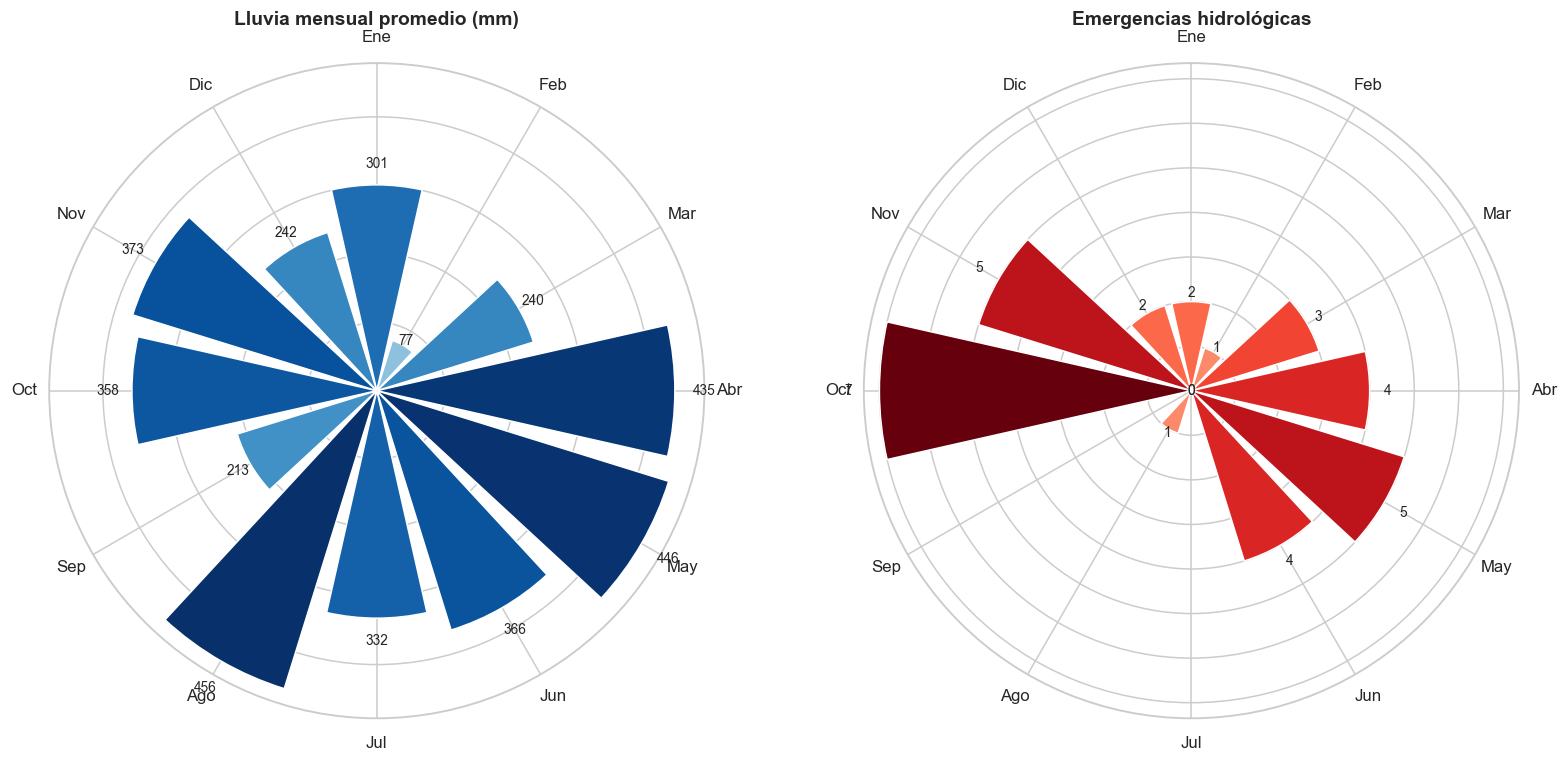

In [57]:
lluvia_mes = (df.groupby(["municipio", "anio", "mes"])["lluvia_mm"].sum(min_count=1)
                .groupby("mes").mean().reindex(range(1, 13)))
eventos_mes = df.groupby("mes")["eventos"].sum().reindex(range(1, 13), fill_value=0)

angulos = np.linspace(0, 2 * np.pi, 12, endpoint=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 7), subplot_kw={"projection": "polar"})

for ax, valores, cmap, titulo in [(axes[0], lluvia_mes, plt.cm.Blues, "Lluvia mensual promedio (mm)"),
                                  (axes[1], eventos_mes, plt.cm.Reds, "Emergencias hidrológicas")]:
    maximo = valores.max() if valores.max() > 0 else 1
    ax.bar(angulos, valores, width=2 * np.pi / 12 * 0.85, color=cmap(0.3 + 0.7 * valores / maximo), edgecolor="white")
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_xticks(angulos)
    ax.set_xticklabels(MESES, fontsize=11)
    ax.set_yticklabels([])
    ax.set_title(titulo, pad=25, fontweight="bold")
    for angulo, valor in zip(angulos, valores):
        ax.text(angulo, valor * 1.1, f"{valor:.0f}", ha="center", va="center", fontsize=9)

plt.tight_layout()
plt.show()

### 8.7 ¿Cuántos días tarda cada río en responder a la lluvia?

Para cada municipio se calcula la correlación entre el nivel del río de hoy y la lluvia de días anteriores.
Solo se incluyen los municipios aptos (con suficientes días de lluvia y nivel a la vez), porque con pocos días la correlación no es confiable.
La celda marcada con → es el **tiempo de respuesta**: cuántos días después de llover sube más el río. Es un dato muy útil para el modelo.

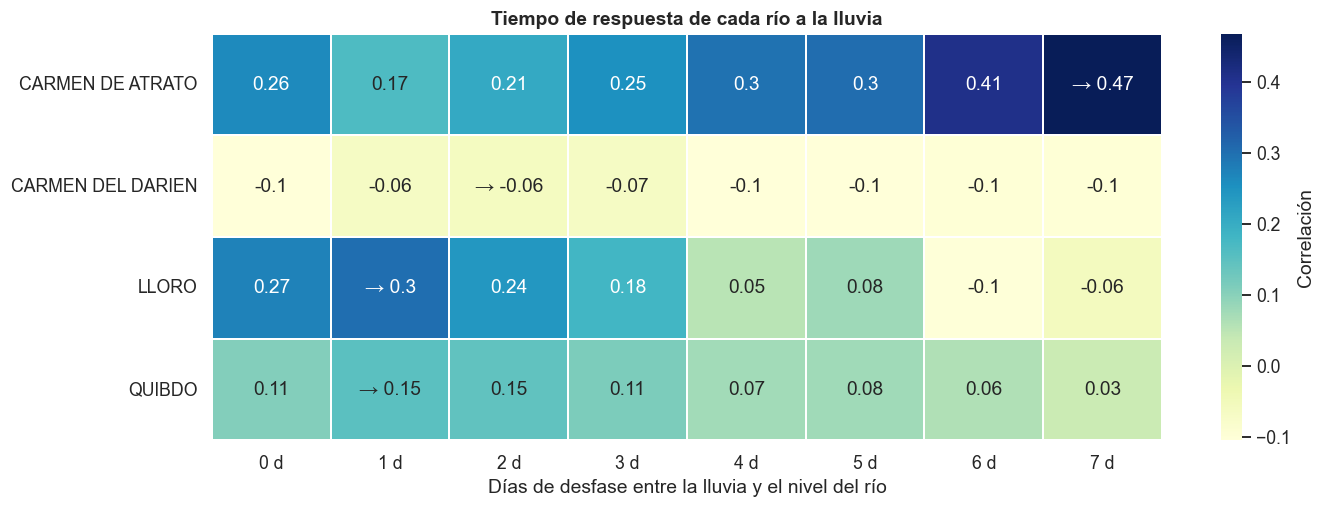

In [58]:
desfases = range(0, 8)
respuesta = pd.DataFrame(index=MUNICIPIOS_MODELO, columns=[f"{k} d" for k in desfases], dtype=float)
for mun in MUNICIPIOS_MODELO:
    d = df[df["municipio"] == mun]
    for k in desfases:
        respuesta.loc[mun, f"{k} d"] = d["nivel_max"].corr(d["lluvia_acum_3d"].shift(k))

etiquetas = respuesta.round(2).astype(str)
for mun in respuesta.index:
    if respuesta.loc[mun].notna().any():
        mejor = respuesta.loc[mun].astype(float).idxmax()
        etiquetas.loc[mun, mejor] = "→ " + etiquetas.loc[mun, mejor]

fig, ax = plt.subplots(figsize=(13, 0.7 * len(respuesta) + 2))
sns.heatmap(respuesta.astype(float), annot=etiquetas.values, fmt="", cmap="YlGnBu", linewidths=1,
            linecolor="white", cbar_kws={"label": "Correlación"}, ax=ax)
ax.set_xlabel("Días de desfase entre la lluvia y el nivel del río")
ax.set_ylabel("")
ax.set_title("Tiempo de respuesta de cada río a la lluvia")
plt.tight_layout()
plt.show()

### 8.8 La zona de riesgo

Cada punto es un municipio apto en un día. En el eje vertical está el **percentil del nivel** (para comparar ríos de distinto tamaño).
La franja superior es la zona de riesgo (por encima del percentil 95). Los círculos rojos son días con emergencia reportada.

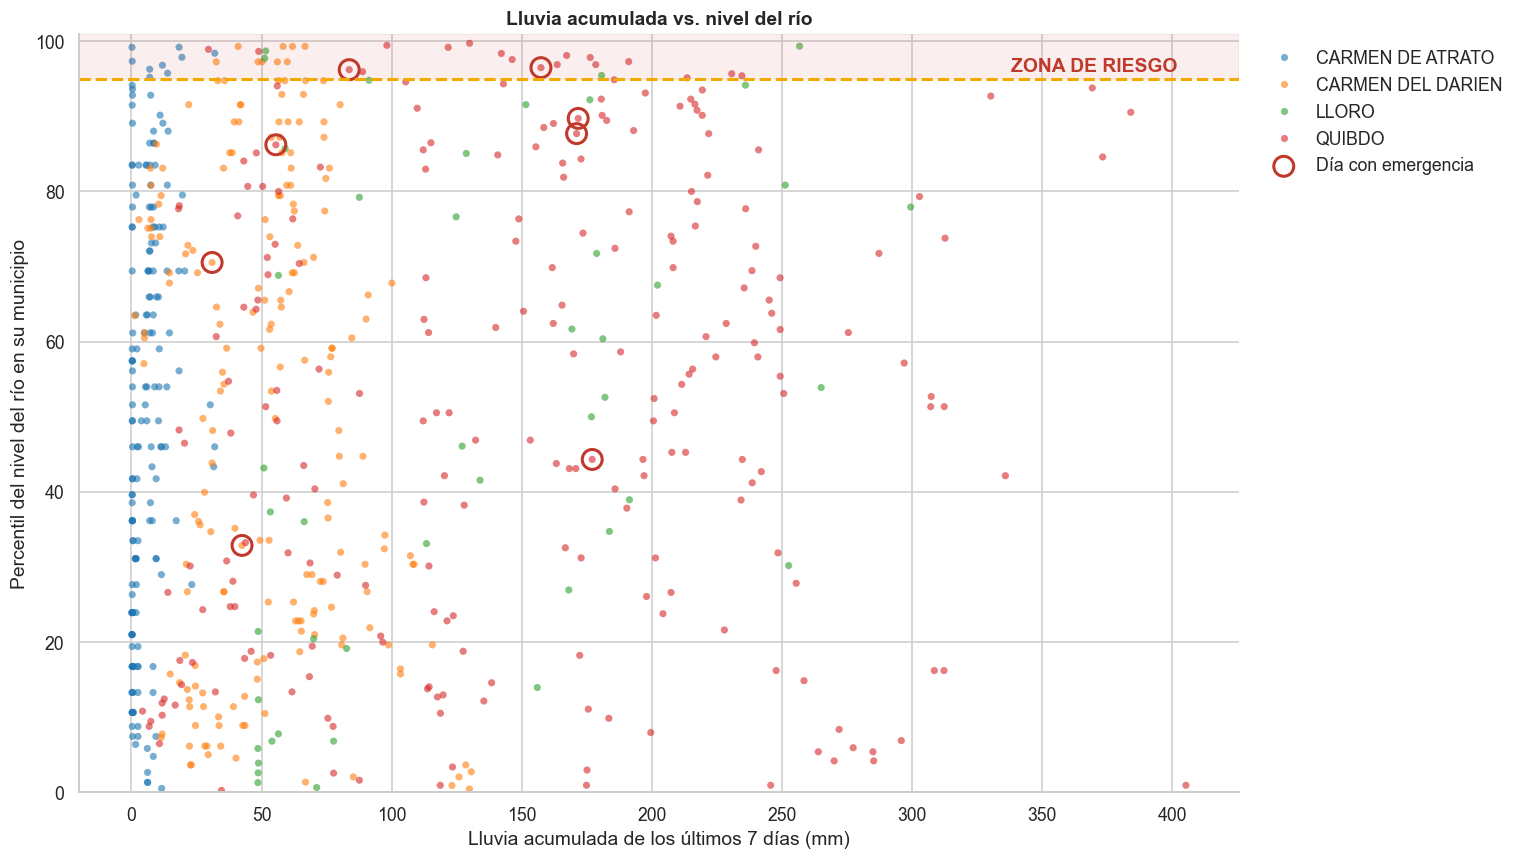

In [59]:
fig, ax = plt.subplots(figsize=(14, 8))
aptos = df[df["apto_modelo"] == 1]
sns.scatterplot(data=aptos, x="lluvia_acum_7d", y="nivel_percentil", hue="municipio",
                palette="tab10", s=22, alpha=0.6, edgecolor="none", ax=ax)

ev = aptos[aptos["hubo_evento"] == 1]
ax.scatter(ev["lluvia_acum_7d"], ev["nivel_percentil"], s=170, facecolor="none",
           edgecolor=ROJO, linewidth=2, label="Día con emergencia")

ax.axhspan(95, 101, color=ROJO, alpha=0.08)
ax.axhline(95, color=AMARILLO, linestyle="--", linewidth=2)
ax.text(aptos["lluvia_acum_7d"].max(), 96, "ZONA DE RIESGO  ", color=ROJO, fontweight="bold", ha="right")

ax.set_ylim(0, 101)
ax.set_xlabel("Lluvia acumulada de los últimos 7 días (mm)")
ax.set_ylabel("Percentil del nivel del río en su municipio")
ax.set_title("Lluvia acumulada vs. nivel del río")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

### 8.9 ¿El nivel alto coincide con las emergencias reales?

Se revisa si los días de nivel alto tienen una emergencia reportada cerca (2 días antes o después), y al revés.
Esto valida si el nivel del río es una buena forma de medir el riesgo para el modelo.

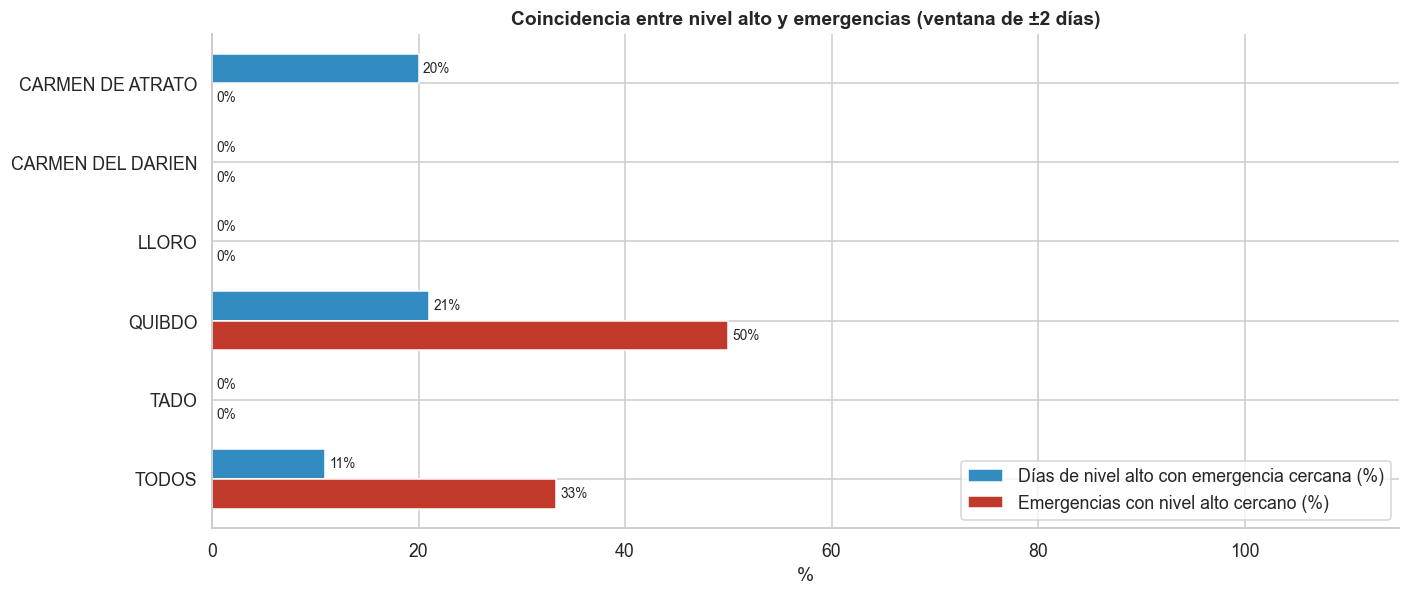

In [60]:
VENTANA = 2   # días antes y después

por_mun = df.groupby("municipio")
df["evento_cercano"] = por_mun["hubo_evento"].transform(
    lambda x: x.rolling(2 * VENTANA + 1, center=True, min_periods=1).max())
df["nivel_alto_cercano"] = por_mun["nivel_alto"].transform(
    lambda x: x.rolling(2 * VENTANA + 1, center=True, min_periods=1).max())

validacion = pd.DataFrame({
    "Días de nivel alto con emergencia cercana (%)":
        df[df["nivel_alto"] == 1].groupby("municipio")["evento_cercano"].mean() * 100,
    "Emergencias con nivel alto cercano (%)":
        df[(df["hubo_evento"] == 1) & df["nivel_max"].notna()].groupby("municipio")["nivel_alto_cercano"].mean() * 100,
}).fillna(0)
validacion.loc["TODOS"] = [
    df[df["nivel_alto"] == 1]["evento_cercano"].mean() * 100,
    df[(df["hubo_evento"] == 1) & df["nivel_max"].notna()]["nivel_alto_cercano"].mean() * 100,
]

fig, ax = plt.subplots(figsize=(13, 0.6 * len(validacion) + 2))
validacion.plot.barh(ax=ax, color=[AZUL_RIO, ROJO], width=0.75)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.0f%%", padding=3, fontsize=9)
ax.set_xlim(0, 115)
ax.set_xlabel("%")
ax.set_ylabel("")
ax.invert_yaxis()
ax.set_title(f"Coincidencia entre nivel alto y emergencias (ventana de ±{VENTANA} días)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 8.10 36 meses en una sola gráfica

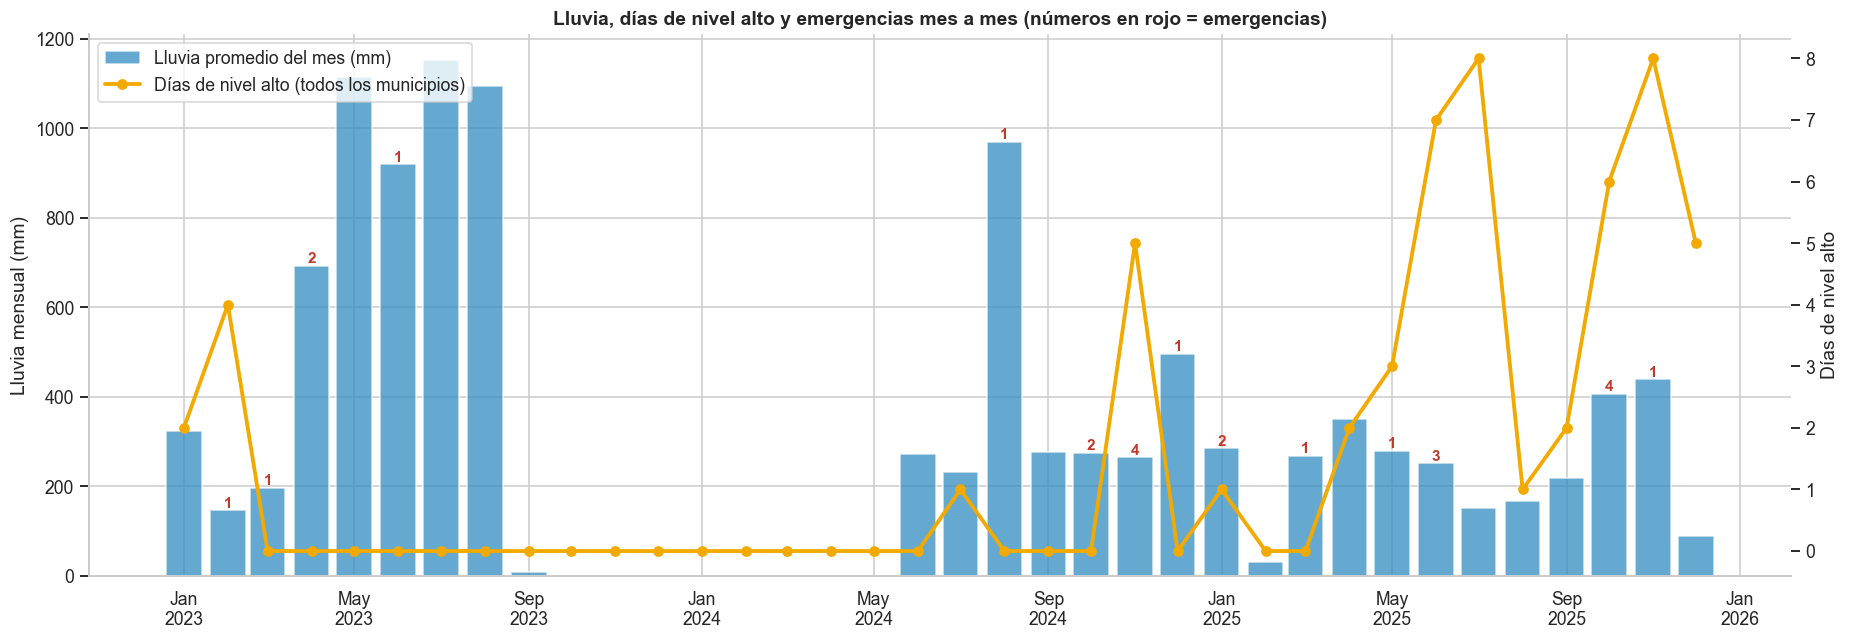

In [61]:
mensual = df.groupby([pd.Grouper(key="fecha", freq="MS"), "municipio"])["lluvia_mm"].sum(min_count=1).groupby("fecha").mean().to_frame()
mensual["eventos"] = df.groupby(pd.Grouper(key="fecha", freq="MS"))["eventos"].sum()
mensual["dias_nivel_alto"] = df.groupby(pd.Grouper(key="fecha", freq="MS"))["nivel_alto"].sum()

fig, ax = plt.subplots(figsize=(17, 6))
ax.bar(mensual.index, mensual["lluvia_mm"], width=25, color=AZUL_RIO, alpha=0.75, label="Lluvia promedio del mes (mm)")
ax.set_ylabel("Lluvia mensual (mm)")

ax2 = ax.twinx()
ax2.plot(mensual.index, mensual["dias_nivel_alto"], color=AMARILLO, marker="o", linewidth=2.5, label="Días de nivel alto (todos los municipios)")
ax2.set_ylabel("Días de nivel alto")
ax2.grid(False)

for fecha, n in mensual["eventos"].items():
    if n > 0:
        ax.text(fecha, mensual.loc[fecha, "lluvia_mm"], f"{int(n)}", ha="center", va="bottom",
                color=ROJO, fontweight="bold", fontsize=10)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
lineas1, etiq1 = ax.get_legend_handles_labels()
lineas2, etiq2 = ax2.get_legend_handles_labels()
ax.legend(lineas1 + lineas2, etiq1 + etiq2, loc="upper left")
ax.set_title("Lluvia, días de nivel alto y emergencias mes a mes (números en rojo = emergencias)")
plt.tight_layout()
plt.show()

### 8.11 Relación entre todas las variables

Se calcula con los municipios aptos. Las variables con mayor correlación con `nivel_percentil` y `nivel_alto` son las mejores candidatas para el modelo.

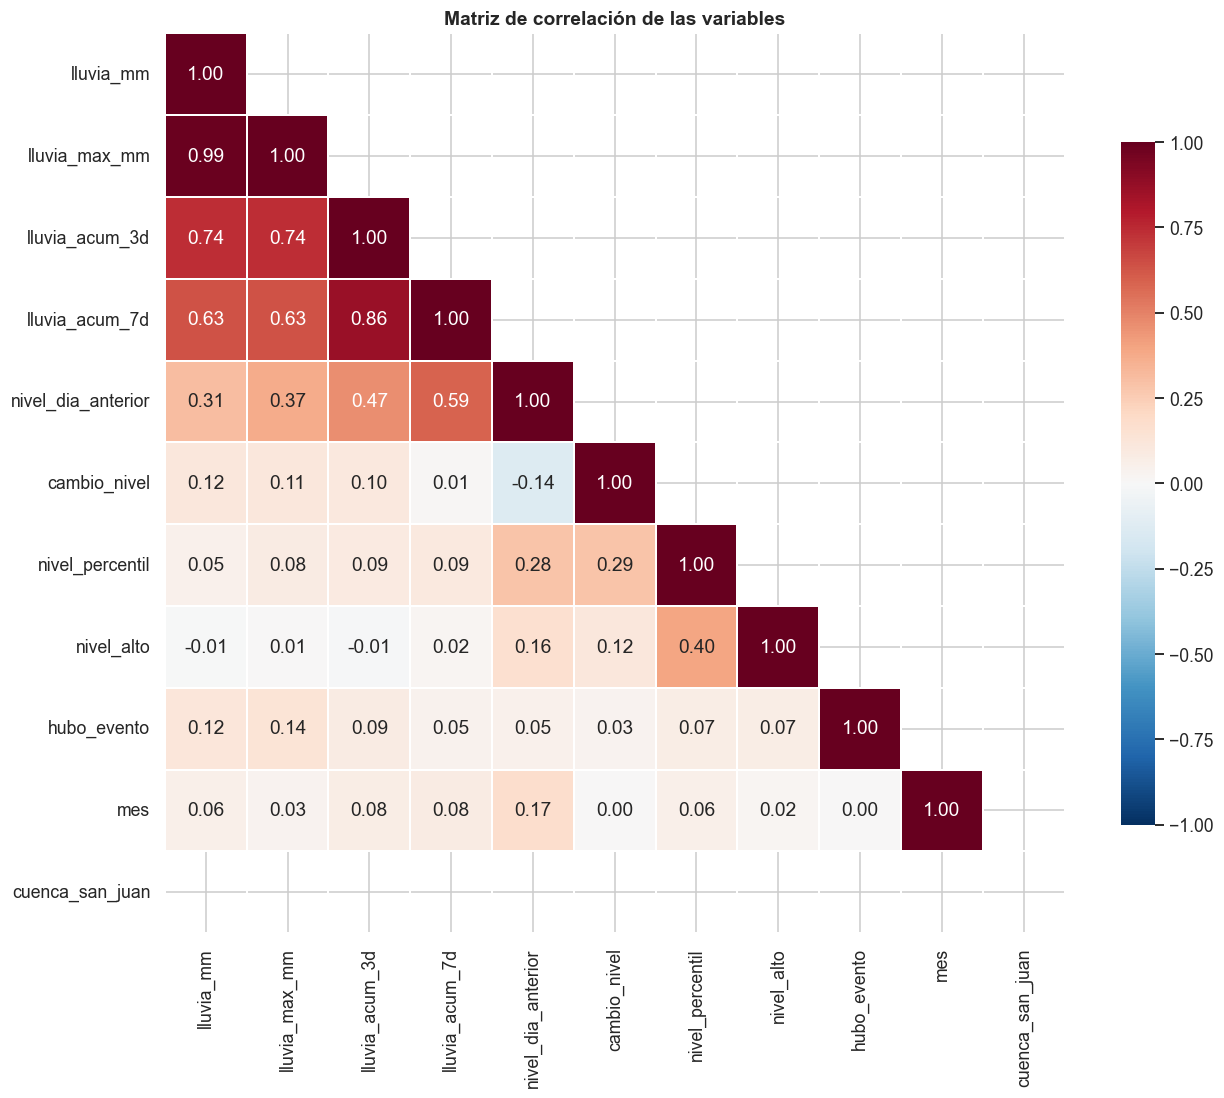

In [62]:
variables = ["lluvia_mm", "lluvia_max_mm", "lluvia_acum_3d", "lluvia_acum_7d", "nivel_dia_anterior",
             "cambio_nivel", "nivel_percentil", "nivel_alto", "hubo_evento", "mes", "cuenca_san_juan"]
correlacion = df[df["apto_modelo"] == 1][variables].corr()
mascara = np.triu(np.ones_like(correlacion, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(correlacion, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=1, cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Matriz de correlación de las variables")
plt.tight_layout()
plt.show()

## 9. Guardar el dataframe para el modelo

In [ ]:
columnas_modelo = ["municipio", "fecha", "anio", "mes", "cuenca_san_juan",
                   "lluvia_mm", "lluvia_max_mm", "estaciones_lluvia", "lluvia_acum_3d", "lluvia_acum_7d",
                   "nivel_max", "nivel_medio", "nivel_min", "nivel_dia_anterior", "cambio_nivel",
                   "nivel_percentil", "umbral_nivel", "eventos", "familias_afectadas",
                   "hubo_evento", "nivel_alto", "apto_modelo"]
df[columnas_modelo].to_csv("datos/datos_municipios_diario.csv", index=False)
print("Archivo guardado: datos_municipios_diario.csv |", len(df), "filas")

Archivo guardado: datos_municipios_diario.csv | 5480 filas


## 10. Conclusiones preliminares

Completen esta sección con lo que muestren sus datos. Preguntas guía:

1. **Cruce de fuentes:** ¿cuántos municipios coinciden en las tres fuentes? ¿Cuántos son de la cuenca del San Juan?
2. **Calidad de los datos:** ¿qué estaciones tienen vacíos importantes? ¿Se encontraron sensores acumulados, duplicados o pegados? ¿Cuántos municipios quedaron aptos para el modelo?
3. **Estacionalidad:** ¿en qué meses llueve más y en qué meses ocurren más emergencias? ¿Coinciden?
4. **Comparación entre municipios:** ¿cuál es el más lluvioso y cuál tiene más emergencias?
5. **Tiempo de respuesta:** ¿cuántos días después de la lluvia sube cada río?
6. **Validación del umbral:** ¿los días de nivel alto coinciden con emergencias reales?
7. **Limitaciones:** reportes incompletos de la UNGRD en zonas rurales, vacíos de las estaciones automáticas, periodo de solo tres años y diferencias entre ríos.